In [1]:
from pathlib import Path
import hashlib
import csv
import io
import json

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
if not ROOT.is_dir():
    raise FileNotFoundError(f"未找到远程项目目录：{ROOT}")

# 1. 核对计划中登记的阶段四归档文件
expected = {
    "report/findings.md":
        "9d256b87f56dc459136e0783750fb8d5076096480673c923ddbc3be0f7d5d083",
    "report/stage4_acceptance.md":
        "d0e41e4223c5f596d106df9fdb50f75cf4e9528d8bbd952cc5054027bfec944b",
    "report/stage4_artifact_index.csv":
        "5dcfcf3384c5963d5d85f95c64ed16a6bbbc95f5a875332b595ca3c74a20f96f",
    "results/stage4_all_comparisons.csv":
        "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f",
    "results/run_manifest.csv":
        "c72cf1a3f36419cb063cf9eb71a87be723efd245195041ecfd02643b6d36f601",
}

print("=== 阶段四来源核对 ===")
for rel, recorded in expected.items():
    path = ROOT / rel
    if not path.is_file():
        print(json.dumps(
            {"file": rel, "status": "MISSING"}, ensure_ascii=False
        ))
        continue
    digest = hashlib.file_digest(path.open("rb"), "sha256").hexdigest()
    print(json.dumps({
        "file": rel,
        "status": "MATCH" if digest == recorded else "CHANGED",
        "sha256": digest,
    }, ensure_ascii=False))

# 2. 查看现有文档、配置、程序与检查入口；不读取密钥或环境变量
print("\n=== 现有材料清单 ===")
for folder in ("report", "configs", "src", "experiments", "tests"):
    base = ROOT / folder
    print(f"\n[{folder}]")
    if not base.is_dir():
        print("MISSING")
        continue
    for path in sorted(base.iterdir()):
        if path.is_file() and path.suffix.lower() in {
            ".md", ".py", ".yaml", ".yml", ".json", ".txt"
        }:
            print(f"{path.relative_to(ROOT)} | {path.stat().st_size} bytes")

print("\n=== 复现基础文件 ===")
for rel in ("README.md", "requirements.txt", "pyproject.toml",
            "requirements.lock", "uv.lock", "main.py"):
    path = ROOT / rel
    print(f"{rel}: {'EXISTS' if path.is_file() else 'MISSING'}")

# 3. 读取写作的核心依据；过长时明确标记，后续再分段读取
for rel in ("report/model.md", "report/assumptions.md",
            "report/findings.md", "report/report.md"):
    print(f"\n=== BEGIN {rel} ===")
    path = ROOT / rel
    if not path.is_file():
        print("MISSING")
    else:
        content = path.read_text(encoding="utf-8-sig")
        limit = 24000
        print(content[:limit])
        if len(content) > limit:
            print(f"\n[未显示完：共 {len(content)} 字符，已显示 {limit} 字符]")
    print(f"=== END {rel} ===")

# 4. 确认实验总表与运行清单的实际结构
for rel in ("results/stage4_all_comparisons.csv",
            "results/run_manifest.csv"):
    print(f"\n=== 表结构：{rel} ===")
    path = ROOT / rel
    if not path.is_file():
        print("MISSING")
        continue
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        columns = reader.fieldnames
        rows = list(reader)
    print("数据行数：", len(rows))
    print("列名：", json.dumps(columns, ensure_ascii=False))
    print("前两行：")
    print(json.dumps(rows[:2], ensure_ascii=False, indent=2))

print("\n资料检查结束；未修改项目文件，未运行实验。")

=== 阶段四来源核对 ===
{"file": "report/findings.md", "status": "MATCH", "sha256": "9d256b87f56dc459136e0783750fb8d5076096480673c923ddbc3be0f7d5d083"}
{"file": "report/stage4_acceptance.md", "status": "MATCH", "sha256": "d0e41e4223c5f596d106df9fdb50f75cf4e9528d8bbd952cc5054027bfec944b"}
{"file": "report/stage4_artifact_index.csv", "status": "MATCH", "sha256": "5dcfcf3384c5963d5d85f95c64ed16a6bbbc95f5a875332b595ca3c74a20f96f"}
{"file": "results/stage4_all_comparisons.csv", "status": "MATCH", "sha256": "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f"}
{"file": "results/run_manifest.csv", "status": "MATCH", "sha256": "c72cf1a3f36419cb063cf9eb71a87be723efd245195041ecfd02643b6d36f601"}

=== 现有材料清单 ===

[report]
report/assumptions.md | 1402 bytes
report/data_dictionary.md | 837 bytes
report/data_profile.md | 1821 bytes
report/findings.md | 13631 bytes
report/model.md | 9678 bytes
report/model_validation.md | 948 bytes
report/stage2_acceptance.md | 858 bytes
report/stage3_acceptanc

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import io
import json
import math
import shutil

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

def digest(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

# 在写入报告前，再次确认正式来源没有改变
expected = {
    "report/findings.md":
        "9d256b87f56dc459136e0783750fb8d5076096480673c923ddbc3be0f7d5d083",
    "report/stage4_acceptance.md":
        "d0e41e4223c5f596d106df9fdb50f75cf4e9528d8bbd952cc5054027bfec944b",
    "report/stage4_artifact_index.csv":
        "5dcfcf3384c5963d5d85f95c64ed16a6bbbc95f5a875332b595ca3c74a20f96f",
    "results/stage4_all_comparisons.csv":
        "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f",
    "results/run_manifest.csv":
        "c72cf1a3f36419cb063cf9eb71a87be723efd245195041ecfd02643b6d36f601",
}
observed = {}
for rel, wanted in expected.items():
    path = ROOT / rel
    if not path.is_file():
        raise FileNotFoundError(rel)
    observed[rel] = digest(path)
    if observed[rel] != wanted:
        raise RuntimeError(f"来源已改变，停止写入并先核查：{rel}")

with (ROOT / "results/stage4_all_comparisons.csv").open(
    encoding="utf-8-sig", newline=""
) as stream:
    results = list(csv.DictReader(stream))

with (ROOT / "results/run_manifest.csv").open(
    encoding="utf-8-sig", newline=""
) as stream:
    manifest = list(csv.DictReader(stream))

if len(results) != 172 or len(manifest) != 172:
    raise RuntimeError("结果或运行清单行数与已验收记录不一致")

e1 = [r for r in results if r["experiment"] == "E1"]
cohorts = ("main_at_arrival", "supplement_after_submission")
methods = ("Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP")
expected_pairs = {(c, m) for c in cohorts for m in methods}
actual_pairs = [(r["cohort"], r["method"]) for r in e1]
if len(e1) != 8 or set(actual_pairs) != expected_pairs:
    raise RuntimeError("E1 的方法或队列组合异常")
e1.sort(key=lambda r: (
    cohorts.index(r["cohort"]), methods.index(r["method"])
))

def number(row, key):
    value = float(row[key])
    if not math.isfinite(value):
        raise ValueError(f"指标不是有限数：{key}")
    return value

def fmt(row, key, digits=3, percent=False):
    raw = row.get(key, "")
    if raw is None or str(raw).strip() in ("", "NA", "nan", "None"):
        return "NA"
    value = number(row, key) * (100 if percent else 1)
    return f"{value:.{digits}f}"

labels = {
    "main_at_arrival": "严格主队列",
    "supplement_after_submission": "晚提交补充队列",
}

def markdown_table(headers, rows):
    return "\n".join([
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
        *["| " + " | ".join(map(str, row)) + " |" for row in rows],
    ])

service_table = markdown_table(
    ["队列", "方法", "费用/USD", "交付/kWh", "缺口/kWh",
     "满足率/%", "全期峰值/kW", "真实离站未完成率/%"],
    [[labels[r["cohort"]], r["method"],
      fmt(r, "cost_USD"), fmt(r, "delivered_kwh"),
      fmt(r, "unmet_kwh"), fmt(r, "energy_satisfaction", percent=True),
      fmt(r, "max_peak_kW"),
      fmt(r, "actual_departure_uncompleted_rate", percent=True)]
     for r in e1],
)

timing_table = markdown_table(
    ["队列", "方法", "活跃决策P95/s", "活跃决策最大耗时/s",
     "离线求解耗时/s", "回退次数"],
    [[labels[r["cohort"]], r["method"],
      fmt(r, "active_P95_seconds", 6),
      fmt(r, "active_max_seconds", 6),
      fmt(r, "offline_solve_wall_seconds", 6),
      r.get("fallback_count", "NA")]
     for r in e1],
)

comparisons = []
for cohort in cohorts:
    lookup = {r["method"]: r for r in e1 if r["cohort"] == cohort}
    uc, rh = lookup["Uncontrolled"], lookup["RH_LP"]
    cost_delta = 100 * (
        number(rh, "cost_USD") / number(uc, "cost_USD") - 1
    )
    peak_delta = 100 * (
        number(rh, "max_peak_kW") / number(uc, "max_peak_kW") - 1
    )
    service_delta = 100 * (
        number(rh, "energy_satisfaction")
        - number(uc, "energy_satisfaction")
    )
    comparisons.append(
        f"- {labels[cohort]}：RH-LP相对Uncontrolled的费用变化为"
        f"{cost_delta:+.3f}%，全期峰值变化为{peak_delta:+.3f}%，"
        f"能量满足率变化为{service_delta:+.3f}个百分点。"
    )

report = r"""# 基于滚动时域线性规划的电动汽车多目标智能充电调度研究

> 工作初稿：背景、数据与模型依据已验收材料整理；主比较表由正式结果总表生成。
> 算法细节仍需与当前源码逐项核对，相关工作、最终图表和复现章节尚待补齐。
> 本文件生成不代表阶段五验收通过。

## 摘要

本文研究Caltech单站历史会话重放下的电动汽车充电调度问题。
采用双层线性规划，先最小化计划未满足电量，再在总缺口容差内权衡费用与日峰值。
滚动控制每15分钟更新一次，仅执行当前计划的首个时段，并依据实际交付更新状态。
实验分别评价到达时已有有效请求的严格主队列和连接后提交请求的补充队列，
比较Uncontrolled、TOU Greedy、完整信息Static LP与RH-LP。

结果显示，费用、峰值和服务水平存在需要联合解释的权衡：
RH-LP在严格主队列中降低全期峰值，同时降低能量满足率；
补充队列中未表现出相对规则基线的全面优势。
受控需求误差和提前离站进一步暴露了可见目标与实际服务之间的差异。
结论限于本次样本、聚合容量和实验电价，不外推为真实站点账单收益或原网络电气可行性。

关键词：电动汽车；滚动时域；线性规划；充电调度；信息可用性；历史重放

## 1 研究背景与问题

### 1.1 研究问题

在设备上限与共享站点容量约束下，调度器需要决定车辆何时充电及充电功率。
请求电量和预计离站提供了计划依据，但真实离站可能提前，用户也可能晚提交或修改输入。
因此，当前计划中的服务优先保证，不能直接等同于真实离站时的服务完成保证。

本文回答三个问题：在相同环境下，四种方法的费用、峰值与服务有何差异；
费用权重及聚合容量如何影响结果；需求估计误差和提前离站如何影响实际交付。

### 1.2 文献与工具基础

ACN-Data提供面向充电研究的公开会话数据及获取接口，
其原始论文介绍了数据及应用[1]。本文使用其中Caltech站点的连续历史区间。
ACN-Sim提供数据驱动的充电仿真环境[2]。
本文采用其相关网络与设备组件，并结合项目事件环境执行历史重放。

本项目的具体信息释放、双层目标和实验设置均以本项目规格与实现为准。
相关工作仍需补充滚动优化与服务约束文献，并明确与本文方法的关系。

### 1.3 研究范围

研究对象为固定车辆—EVSE连接下的单站连续功率调度。
不建模充电桩分配、V2G、储能、光伏、电池SOC或老化。
负荷仅指EV充电负荷，不包含建筑基础负荷。
基础模型未施加原Caltech支路与相位约束，不能据此证明原网络电气可行。

## 2 数据与实验假设

### 2.1 数据来源及样本形成

数据为Caltech单站历史会话，当地时间区间为
[2019-05-06, 2019-07-29)，共12周，原始记录2434条。
其中123条到达时已有有效输入，1956条在连接后才获得有效输入，
355条连接期间无可用请求而排除。
候选2079条中另排除4条跨集合末端边界会话，最终保留2075条。

最终严格主队列122条、晚提交补充队列1953条。
未使用历史最终交付电量代替缺失请求，也未开展缺失需求估计实验。
到达时输入覆盖有限，两个队列存在选择差异，分别运行与评价。

### 2.2 时间划分

| 集合 | 当地日期区间，右端不含 | 严格主队列 | 补充队列 |
| --- | --- | --- | --- |
| 开发 | 2019-05-06至2019-06-24 | 64 | 1227 |
| 验证 | 2019-06-24至2019-07-08 | 19 | 258 |
| 测试 | 2019-07-08至2019-07-29 | 39 | 468 |

采用连续时间划分。测试期含21个完整自然日；
严格主队列测试样本仅39条，不作全站用户普遍性推断。
时间计算使用UTC，电价和自然日归属使用America/Los_Angeles，
不假定所有当地自然日均有96个时段。

### 2.3 信息可用性

严格主队列冻结到达时有效总请求与预计离站，后续修改仅审计。
补充队列仅在输入实际生效后释放请求，采用当前最新有效输入；
首次输入前不供电。请求表示会话累计总目标，而非新增电量。

补充队列最终评价目标为真实离站前最后有效总请求。
该事后目标供评价与静态参考使用，不能提前传给在线控制器。
真实离站由环境在发生时执行；历史kWhDelivered不参与本次累计交付。

### 2.4 设备、容量与电价

设备功率上限为6.656 kW，对应208 V、32 A及功率因数1的换算约定。
电网侧效率固定为1。观测51个stationID与参考配置完成映射；
参考配置包含54个EVSE和8条网络约束，但基础实验使用聚合容量模型。

基准容量50 kW，容量敏感性为37.5、50和62.5 kW，均属于实验情景。
实验TOU按当地时间每日重复：

| 当地时段 | 电价/USD每kWh |
| --- | --- |
| 00:00–08:00 | 0.12 |
| 08:00–16:00 | 0.24 |
| 16:00–21:00 | 0.40 |
| 21:00–24:00 | 0.24 |

电价不区分周末与节假日，不含需量费、税费，不代表Caltech实际账单。

## 3 双层线性规划模型

### 3.1 符号与状态

设当前模型中的会话集合为I，完整15分钟时段集合为T，
涉及的当地自然日集合为D，时段长度Δt=0.25 h。
a_it为计划可用标记，P_i^max为设备功率上限，P_t^station为聚合容量，
c_t为电价，b_d为当天已经实际发生的EV峰值。

在控制时刻k，以Q_i(k)表示可见总请求，D_i(k)表示本次仿真实际累计交付，
剩余需求为：

$$R_i(k)=\max\{Q_i(k)-D_i(k),0\}.$$

无有效输入时不作为可调度需求。请求下调至已交付量以下后停止继续供电，
已发生的超额单独审计，不能通过负功率撤回。

### 3.2 变量与约束

变量为功率p_it≥0、计划缺口u_i≥0和日峰值上界z_d≥0。

$$0\le p_{it}\le a_{it}P_i^{\max}.$$

$$\sum_i p_{it}\le P_t^{\mathrm{station}}.$$

$$\sum_t p_{it}\Delta t+u_i=R_i,\qquad 0\le u_i\le R_i.$$

$$z_d\ge\sum_i p_{it}\quad(t\text{属于}d),\qquad z_d\ge b_d.$$

需求等式与非负缺口保证本次计划交付不超过当前剩余请求。
这里的防超额针对当前可见请求；后续需求下调可能造成不可逆服务超额。

### 3.3 两层目标

第一层最小化总计划缺口：

$$U^*=\min\sum_i u_i.$$

第一层确认最优后，第二层加入：

$$\sum_i u_i\le U^*+\varepsilon_U.$$

随后最小化：

$$J=\alpha\frac{C}{C_{\mathrm{ref}}}
 +(1-\alpha)\sum_{d\in D}\frac{z_d}{P_{\mathrm{ref}}},$$

$$C=\sum_t c_t\Delta t\sum_i p_{it}.$$

正式参考值为C_ref=2.88 USD、P_ref=6.656 kW，
来自开发集严格主队列容量受限Uncontrolled的全日指标中位数，包含无车日，
此后对所有队列、方法与情景固定。第二层服务容差为1e-5 kWh；
服务完成评价容差0.01 kWh另行使用，具体配置待当前文件核对。

峰值项是优化代理项，不能计入实际电费。
总缺口最小不等于逐车公平，也不保证在线实际离站缺口最小。

## 4 方法与统一仿真

### 4.1 四种方法

Uncontrolled在设备、连接和共享容量限制下尽早供电。
TOU Greedy根据当前可见信息与电价构造规则计划。
二者冲突排序及TOU分配细节待与baselines.py逐项核对。

Static LP使用真实连接区间及统一事后评价目标，属于完整信息离线参考。
其供电网格只包括真实连接范围内的完整时段；
在线方法可在实际时段中途离站前获得部分时段交付。
因此，不能未经可行域核对将静态缺口作为在线实际缺口下界。

RH-LP仅纳入当前已连接且已有有效输入的车辆，不预测未来新到达车辆。
每15分钟求解一次，仅执行首个时段，并以实际反馈更新状态。

### 4.2 窗口与事件处理

基础窗口为24小时，并延伸至当前可见有效预计离站所需的完整计划范围。
预计离站已过而车辆仍在场且未完成时，按预设规则延长一个控制时段。
不使用真实未来离站修正可见预测。

同刻事件按离站、到达、输入修改顺序处理，离站时刻更新不生效。
跨日保持累计交付，日峰值分别累计。
实际执行遇到真实离站立即停止供电，以实际持续时间积分。
求解预算、状态保护、回退和具体接口待与当前控制器源码核对。

## 5 实验设计与评价

主实验固定α=0.5、容量50 kW、控制间隔15分钟与基础窗口24小时。
权重实验使用0.2、0.5、0.8；容量实验使用37.5、50、62.5 kW。
需求误差采用10%和20%幅度、10个配对种子；
提前离站分别为15和30分钟，与需求误差分开运行。
零误差参考复用E1，入口等价性做过小样本验证，不称为全量零组重跑。

正式归档包括27个运行、172组方法／队列／情景结果，
其中E1为8组、E2为16组、E3为16组、E4为132组。
运行清单有172行，对应结果组合，不表示172个独立运行。

实际费用由实际电网功率与持续时间积分。
缺口与能量满足率定义为：

$$U_{\mathrm{actual}}=\sum_i\max(E_{\mathrm{eval},i}-E_{\mathrm{delivered},i},0),$$

$$S=\frac{\sum_i\min(E_{\mathrm{delivered},i},E_{\mathrm{eval},i})}
{\sum_iE_{\mathrm{eval},i}}.$$

逐车截断避免某车超额抵消其他车辆不足。
另外报告真实离站与预计离站检查点未完成率、个体服务、
硬约束残差、计算耗时和回退。
预计离站检查点目标及不可评价分母须与metrics.py核对。

## 6 实验结果与讨论

### 6.1 四方法主比较

以下表格直接从已核验的stage4_all_comparisons.csv中筛选E1生成。
数值显示经过舍入，内部计算使用原始精度。

__SERVICE_TABLE__

__COMPARISONS__

费用差伴随服务变化，不能直接解释为同等服务节费。
严格主队列中RH-LP降低全期峰值，但增加实际缺口；
补充队列中RH-LP与Uncontrolled均达到50 kW全期峰值。

### 6.2 计算性能

__TIMING_TABLE__

表中在线活跃决策耗时与离线求解耗时分别呈现。
Static LP执行时的查表耗时不能代表其完整离线计算成本。
具体计时边界和硬件信息待结合源码与运行日志核对。

### 6.3 权重、容量和误差分析

已验收发现显示，RH实际费用与服务不随权重呈简单单调关系；
三个权重点不能称为完整Pareto前沿。
主队列在本次容量网格下结果不变，补充队列容量增加时服务改善。

需求误差增大时，三种在线方法的平均满足率下降，缺口和超额增加。
RH绝对服务较低，并不意味着相对自身零误差基准的增量退化始终更大。
提前离站30分钟时，RH主队列和补充队列满足率分别下降约5.874和4.930个百分点。
本节详细统计表及最终图表将在完整结果核对后补入。

### 6.4 轨迹案例

已有8个定向比较，涉及7个不同会话。
案例支持区分设备与时长导致的不可避免缺口、调度延后、
提前离站损失及需求误差影响。
定向案例不作为随机代表样本；尾段能量恒等分解不作为独立因果识别。
案例图与逐段证据将在后续核对后补入。

## 7 局限与结论

测试严格主队列仅39条，两个队列分别解释。
测试期只有三个完整周，10种子标准差描述固定日期下的合成误差波动，
不是跨日期或跨站点置信区间，不强行宣称显著性。

连续功率、固定效率、聚合容量和实验TOU限制了工程外推范围。
需求误差属于受控合成机制，未验证真实可部署预测器。
E5计算网格／窗口扩展与E6电价／非理想响应扩展未开展。

本次结果表明，在可见信息与真实离站不同的条件下，
计划内服务优先不足以保证实际服务优势。
应同时评价服务、费用与峰值，并保留无优势结果和失败案例。

## 8 复现与交付

待完成：锁定依赖、数据获取与快照说明、确切运行命令、
独立演示配置、图表重生成、干净环境验证及最终成果索引。
既有独立进程检查不替代本阶段的干净环境复现。

## 参考文献

[1] Lee, Z. J., Li, T., and Low, S. H.
ACN-Data: Analysis and Applications of an Open EV Charging Dataset.
ACM e-Energy, 2019.
https://doi.org/10.1145/3307772.3328313

[2] ACN-Sim官方介绍及原始论文入口：
https://ev.caltech.edu/simulator.html
https://ev.caltech.edu/assets/pub/ACN_Sim_Open_Source_Simulator.pdf

参考资料核查日期：2026-11-16。
相关工作及文献书目信息仍需进一步完善。
"""
report = (
    report.replace("__SERVICE_TABLE__", service_table)
    .replace("__COMPARISONS__", "\n".join(comparisons))
    .replace("__TIMING_TABLE__", timing_table)
)

evidence_rows = [
    ("数据与划分", "report/data_profile.md", "待读取全文核对"),
    ("字段与信息", "report/data_dictionary.md", "待读取全文核对"),
    ("假设与边界", "report/assumptions.md", "已回传全文"),
    ("数学规格", "report/model.md", "历史阶段规格；正式参数另核"),
    ("正式参数", "configs/final.yaml", "待读取"),
    ("归一化", "configs/normalization.yaml", "待读取"),
    ("规则基线", "src/baselines.py", "待读取"),
    ("RH流程", "src/rolling_horizon.py", "待读取"),
    ("LP实现", "src/optimization_model.py", "待读取"),
    ("指标", "src/metrics.py", "待读取"),
    ("结果表", "results/stage4_all_comparisons.csv", "哈希核验；E1自动取数"),
    ("运行来源", "results/run_manifest.csv", "哈希核验；172行结果组合"),
    ("结果解释", "report/findings.md", "哈希核验且已回传全文"),
    ("案例", "experiments/inspect_stage4_cases.py", "案例实现与图待核对"),
    ("阶段四验收", "report/stage4_acceptance.md", "哈希核验"),
    ("阶段四索引", "report/stage4_artifact_index.csv", "哈希核验"),
]
buffer = io.StringIO(newline="")
writer = csv.writer(buffer)
writer.writerow(["report_topic", "source_file", "review_status"])
writer.writerows(evidence_rows)

# 保留来源指纹，便于后续查明初稿依据
for _, rel, _ in evidence_rows:
    path = ROOT / rel
    if path.is_file() and rel not in observed:
        observed[rel] = digest(path)

check = {
    "created_at_utc": STAMP,
    "status": "draft_prepared_not_accepted",
    "stage4_frozen_hashes_match": True,
    "result_rows": len(results),
    "manifest_rows": len(manifest),
    "E1_rows": len(e1),
    "source_sha256": observed,
    "pending": [
        "核对当前配置、基线、控制器、LP及指标源码",
        "补充相关工作与文献",
        "核对完整敏感性、误差、案例及最终图表",
        "完成README和干净环境复现",
    ],
}
payloads = {
    "report/report.md": report,
    "report/report_evidence_map.csv": buffer.getvalue(),
    "report/stage5_material_check.json":
        json.dumps(check, ensure_ascii=False, indent=2) + "\n",
}
backup_dir = ROOT / "results/logs" / f"stage5_draft_{STAMP}" / "before"
for rel, content in payloads.items():
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        target = backup_dir / rel
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, target)
    path.write_text(content, encoding="utf-8")

print("=== 初稿写入核对 ===")
for rel in payloads:
    path = ROOT / rel
    print(json.dumps({
        "file": rel,
        "bytes": path.stat().st_size,
        "sha256": digest(path),
    }, ensure_ascii=False))
print("E1自动生成行数：", len(e1))
print("初稿状态：待源码、图表和复现核对；未登记验收通过")

# 下面的输出用于下一步核对；不修改已有配置和源码
for rel in (
    "report/data_profile.md",
    "report/data_dictionary.md",
    "configs/final.yaml",
    "configs/normalization.yaml",
    "src/baselines.py",
    "src/rolling_horizon.py",
):
    print(f"\n=== BEGIN {rel} ===")
    path = ROOT / rel
    print(path.read_text(encoding="utf-8-sig") if path.is_file() else "MISSING")
    print(f"=== END {rel} ===")

=== 初稿写入核对 ===
{"file": "report/report.md", "bytes": 14655, "sha256": "2e532020a5927fc42301ae205576532feddae6a3230451798e5f5e5a2ea5044e"}
{"file": "report/report_evidence_map.csv", "bytes": 952, "sha256": "c6918f9f266a3f7bb85992d8cd54257baeb4a231ce1a6b005afa4c8468aad696"}
{"file": "report/stage5_material_check.json", "bytes": 2031, "sha256": "3f5cdc782670e7fdf78353a0e71e090e1d521e2d75f95f3041d581913b248e8e"}
E1自动生成行数： 8
初稿状态：待源码、图表和复现核对；未登记验收通过

=== BEGIN report/data_profile.md ===
# 数据画像与阶段一记录

数据区间：洛杉矶当地 2019-05-06 至 2019-07-29，右端不含。
原始会话 2434；无可用输入排除 355；跨集合边界排除 4；
最终候选 2075。未发现重复会话或 EVSE 占用重叠。

## 队列与划分

    cohort       main_at_arrival  supplement_after_submission
    split                                                    
    development               64                         1227
    validation                19                          258
    test                      39                          468

严格主队列 122 条，占原始会话约 5.01%，存在信息提交选择偏差。
补充队列 1953 条，信息只能在 modifiedAt 生效后使用。


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil
import pandas as pd

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
LOG = ROOT / "results/logs" / f"stage5_report_revision_{STAMP}"
LOG.mkdir(parents=True, exist_ok=False)

def sha(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

expected = {
    "results/stage4_all_comparisons.csv":
        "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f",
    "report/findings.md":
        "9d256b87f56dc459136e0783750fb8d5076096480673c923ddbc3be0f7d5d083",
}
for rel, wanted in expected.items():
    if sha(ROOT / rel) != wanted:
        raise RuntimeError(f"正式来源已改变，停止修订：{rel}")

report_path = ROOT / "report/report.md"
if sha(report_path) != "2e532020a5927fc42301ae205576532feddae6a3230451798e5f5e5a2ea5044e":
    raise RuntimeError("报告已在首版之后被修改，请先核对，避免覆盖编辑")

df = pd.read_csv(ROOT / "results/stage4_all_comparisons.csv")
if len(df) != 172:
    raise RuntimeError("正式结果行数异常")

# 先完成数据结构检查，再写文件
e1 = df.loc[df.experiment.eq("E1")].copy()
online = e1.loc[e1.method.ne("Static_LP")].copy()
if len(e1) != 8 or len(online) != 6:
    raise RuntimeError("主实验参考组合异常")

sensitivity = df.loc[df.experiment.isin(["E1", "E2", "E3"])].copy()
amplitudes = pd.to_numeric(df["amplitude"], errors="coerce")
advances = pd.to_numeric(df["advance_minutes"], errors="coerce")
noise = df.loc[df.experiment.eq("E4") & amplitudes.gt(0)].copy()
early = df.loc[df.experiment.eq("E4") & advances.gt(0)].copy()

if (len(sensitivity), len(noise), len(early)) != (40, 120, 12):
    raise RuntimeError(
        f"分组数量异常：{len(sensitivity)}, {len(noise)}, {len(early)}"
    )

keys = ["cohort", "method"]
group_keys = keys + ["amplitude"]
sizes = noise.groupby(group_keys, dropna=False).size()
if len(sizes) != 12 or not sizes.eq(10).all():
    raise RuntimeError("需求误差不是12组、每组10个种子")
if noise.duplicated(group_keys + ["seed"]).any():
    raise RuntimeError("误差组存在重复种子")

stats = noise.groupby(group_keys, as_index=False).agg(
    seed_count=("seed", "nunique"),
    cost_mean_USD=("cost_USD", "mean"),
    unmet_mean_kwh=("unmet_kwh", "mean"),
    excess_mean_kwh=("excess_kwh", "mean"),
    satisfaction_mean=("energy_satisfaction", "mean"),
    satisfaction_SD=("energy_satisfaction", "std"),
)
if not stats.seed_count.eq(10).all():
    raise RuntimeError("每组独立种子数量不是10")

reference = online[
    keys + ["cost_USD", "unmet_kwh", "energy_satisfaction"]
].rename(columns={
    "cost_USD": "reference_cost_USD",
    "unmet_kwh": "reference_unmet_kwh",
    "energy_satisfaction": "reference_satisfaction",
})
stats = stats.merge(reference, on=keys, validate="many_to_one")
stats["satisfaction_mean_pct"] = stats.satisfaction_mean * 100
stats["satisfaction_SD_pp"] = stats.satisfaction_SD * 100
stats["delta_satisfaction_pp"] = (
    stats.satisfaction_mean - stats.reference_satisfaction
) * 100
stats["delta_unmet_kwh"] = (
    stats.unmet_mean_kwh - stats.reference_unmet_kwh
)

early = early.merge(reference, on=keys, validate="many_to_one")
early["delta_satisfaction_pp"] = (
    early.energy_satisfaction - early.reference_satisfaction
) * 100
early["delta_unmet_kwh"] = early.unmet_kwh - early.reference_unmet_kwh

labels = {
    "main_at_arrival": "严格主队列",
    "supplement_after_submission": "晚提交补充队列",
}

def table(frame, fields):
    headers = [label for _, label, _ in fields]
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    for _, row in frame.iterrows():
        cells = []
        for key, _, scale in fields:
            value = row[key]
            if pd.isna(value):
                cells.append("NA")
            elif key == "cohort":
                cells.append(labels.get(value, str(value)))
            elif scale is None:
                cells.append(str(value))
            else:
                cells.append(f"{float(value) * scale:.3f}")
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

sensitivity_table = table(
    sensitivity.sort_values(["cohort", "scenario_id", "method"]),
    [
        ("scenario_id", "情景", None),
        ("cohort", "队列", None),
        ("method", "方法", None),
        ("alpha", "α", 1),
        ("capacity_kw", "容量/kW", 1),
        ("cost_USD", "费用/USD", 1),
        ("unmet_kwh", "缺口/kWh", 1),
        ("energy_satisfaction", "满足率/%", 100),
        ("max_peak_kW", "全期峰值/kW", 1),
    ],
)
noise_table = table(
    stats.sort_values(group_keys),
    [
        ("cohort", "队列", None),
        ("method", "方法", None),
        ("amplitude", "幅度/%", 100),
        ("cost_mean_USD", "平均费用/USD", 1),
        ("unmet_mean_kwh", "平均缺口/kWh", 1),
        ("excess_mean_kwh", "平均超额/kWh", 1),
        ("satisfaction_mean_pct", "平均满足率/%", 1),
        ("satisfaction_SD_pp", "种子标准差/百分点", 1),
        ("delta_satisfaction_pp", "较自身E1变化/百分点", 1),
    ],
)
early_table = table(
    early.sort_values(keys + ["advance_minutes"]),
    [
        ("cohort", "队列", None),
        ("method", "方法", None),
        ("advance_minutes", "提前/min", 1),
        ("cost_USD", "费用/USD", 1),
        ("unmet_kwh", "缺口/kWh", 1),
        ("energy_satisfaction", "满足率/%", 100),
        ("delta_satisfaction_pp", "较自身E1变化/百分点", 1),
        ("delta_unmet_kwh", "新增缺口/kWh", 1),
    ],
)

report = report_path.read_text(encoding="utf-8")

def replace_section(text, start, end, replacement):
    if text.count(start) != 1 or text.count(end) != 1:
        raise RuntimeError(f"章节定位异常：{start}")
    a, b = text.index(start), text.index(end)
    if b <= a:
        raise RuntimeError("章节顺序异常")
    return text[:a] + replacement.rstrip() + "\n\n" + text[b:]

methods = r"""### 4.1 四种方法

Uncontrolled仅消费当前可见状态，按到达时间、会话编号依次分配容量。
每车当前时段功率为设备上限、剩余站点容量和剩余需求除以0.25小时三者的最小值。
未获得有效请求、已满足请求或尚未到达完整控制网格的车辆不参与分配。

TOU Greedy每次为当前可见车辆重建计划。
车辆按原始可见预计离站、到达时间、会话编号排序；
每车可用时段按电价、时段开始时间排序，
依次分配受设备上限、该时段剩余容量与剩余需求限制的功率。
该方法仅执行首个时段，不预测未来新车；同价时优先较早时段。
预计离站已过的车辆延长一个时段；
预计离站尚未到达时，向下取整后的不足整格尾段不提前启用逾期规则。

Static LP使用真实连接区间及统一事后评价目标，属于完整信息离线参考。
其可用范围仅含真实连接范围内的完整时段；
在线方法执行时遇到实际离站，可获得离站前的部分时段交付。
两者可行域口径有差异，不能自动把静态缺口视为在线实际缺口下界。

RH-LP仅纳入当前已连接、已有有效输入且仍有需求的车辆。
每15分钟构建一次双层LP，求解并校验完整导出计划后，仅执行首个时段。
剩余需求使用本次仿真的实际累计交付更新，不读取历史最终交付。
已发生峰值由实际执行分段按当地自然日累计，不由预测峰值更新。

### 4.2 窗口、预算与回退

基础窗口24小时，末端扩展到当前可见预计离站所需的完整计划范围。
预计离站已过但车辆仍在场时，按预设规则延长一个控制时段。
窗口延伸不使用未来真实离站或未来车辆信息。

在线决策采用30秒预算，控制器在构建案例后扣除已用时间，
将剩余预算传给独立求解进程；求解后及计划校验后再次检查预算。
只有两层均报告最优且计划校验通过，才执行LP首步。
计划校验涵盖设备、可用时段、站点容量、能量积分及需求上限；
仅对容差尺度的首步误差进行修正并保留原始文件。

超时、求解异常或计划校验失败时记录错误并回退：
按可见预计离站、到达时间、会话编号排序，在可用首时段内依次供电，
同时满足设备、剩余站点容量和当前剩余需求限制。
30秒是正常LP决策路径的预算；
异常记录和回退处理仍有额外开销，不将其称为严格的端到端耗时上界。
LP内部两层如何共享剩余求解预算，仍需核对优化核心。

同刻事件顺序及环境执行规则依据模型规格：
离站、到达、输入修改；离站时刻更新不生效。
跨日保持累计交付，真实离站发生时停止供电并按实际持续时间积分。
环境与指标的具体实现仍需进一步核对。
"""
report = replace_section(
    report, "### 4.1 四种方法", "## 5 实验设计与评价", methods
)

results_text = """### 6.3 权重与容量

下表包含E1参考及E2、E3的四种方法，共40组结果。
参考只保留一份，不把复用参考计为新增实验。

""" + sensitivity_table + """

RH实际费用与服务不随权重呈简单单调关系。
三个权重点不能称为完整Pareto前沿。
主队列在本次容量网格下结果不变，补充队列容量增加时服务改善；
低容量情景下的较低费用必须结合更多缺口解释。

### 6.4 需求估计误差

每个队列、方法与幅度组合包含10个配对种子。
下表标准差采用样本标准差（ddof=1），满足率变化相对各方法自身E1参考。
原始评价目标保持不变，超额交付不能抵消其他车辆缺口。

""" + noise_table + """

误差增大时，三种在线方法平均满足率下降，缺口和超额增加。
RH绝对服务水平较低，与相对自身基准的增量退化是不同问题，
不能仅由绝对排名断言RH对误差始终更敏感。
补充队列中，已验收发现显示RH相对TOU平均费用较高、满足率较低。

标准差描述固定测试日期下合成扰动的种子间波动，
不是跨日期或跨站点置信区间，也不据此宣称统计显著性。

### 6.5 提前离站

实际离站提前15或30分钟，调度器可见预计离站保持不变。
下表变化量均相对同一方法、同一队列的E1参考。

""" + early_table + """

提前30分钟时，RH主队列和补充队列满足率分别下降约5.874和4.930个百分点，
均大于本次规则基线的降幅。
费用下降伴随交付减少，不能单独视作调度收益。

### 6.6 轨迹案例

"""
findings = (ROOT / "report/findings.md").read_text(encoding="utf-8")
case_start = findings.index("## 轨迹案例") + len("## 轨迹案例")
case_end = findings.index("## 统计与适用边界", case_start)
results_text += findings[case_start:case_end].strip() + "\n"

figures = [
    (
        "results/logs/stage4_acceptance_20261114T124214068797Z/"
        "E1_first_test_day.png",
        "图1 固定规则选择的测试首日EV负荷示例。"
        "该图只展示首日轨迹，不代替21日总体评价。",
    ),
    (
        "results/logs/stage4_sensitivity_20261112T124051538161Z/"
        "weight_plot_20261113T090431403581Z/weight_cost_peak.png",
        "图2 已验收的最终权重—费用—峰值图。"
        "权重点限于预设网格，解释时结合服务指标。",
    ),
]
results_text += "\n### 6.7 已归档图表\n\n"
for rel, caption in figures:
    if not (ROOT / rel).is_file():
        raise FileNotFoundError(f"已登记最终图缺失：{rel}")
    results_text += f"![{caption}](../{rel})\n\n{caption}\n\n"

report = replace_section(
    report, "### 6.3 权重、容量和误差分析",
    "## 7 局限与结论", results_text
)
report = report.replace(
    "服务完成评价容差0.01 kWh另行使用，具体配置待当前文件核对。",
    "服务完成评价容差0.01 kWh另行使用，二者已与冻结配置核对。"
)
report = report.replace(
    "> 算法细节仍需与当前源码逐项核对，相关工作、最终图表和复现章节尚待补齐。",
    "> 基线及RH控制器已与回传源码核对；敏感性与误差表已由正式结果生成。\n"
    "> 优化核心、指标与计时边界、相关工作、其余图表及复现章节仍待完成。"
)

# 补齐供核对的约束、回退和复核标记，不把重复运行分段相加
audit_columns = [
    "station_violation_segments", "device_violation_segments",
    "connection_violation_segments", "max_power_violation_kW",
    "max_energy_residual_kwh", "fallback_count",
]
summary = {}
for col in audit_columns:
    values = pd.to_numeric(df[col], errors="raise")
    if values.isna().any():
        raise RuntimeError(f"审计列存在空值：{col}")
    summary[col] = {
        "maximum_across_result_rows": float(values.max()),
        "positive_result_rows": int(values.gt(0).sum()),
    }
review = df["requires_review"].astype(str).str.strip().str.lower()
if not review.isin(["true", "false"]).all():
    raise RuntimeError("requires_review存在未知值")
summary["requires_review_rows"] = int(review.eq("true").sum())

tables = {
    "report/tables/sensitivity_all_methods.csv": sensitivity,
    "report/tables/demand_error_seed_statistics.csv": stats,
    "report/tables/early_departure_comparisons.csv": early,
}
writes = {"report/report.md": report}
for rel, frame in tables.items():
    writes[rel] = frame.to_csv(index=False)

for rel, content in writes.items():
    path = ROOT / rel
    if path.exists():
        backup = LOG / "before" / rel
        backup.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, backup)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content, encoding="utf-8")

# 列出已知汇总目录中的其余图片，后续确认最终版本及说明
image_candidates = []
image_dirs = [
    "results/logs/stage4_sensitivity_20261112T124051538161Z/"
    "summary_20261113T083157781711Z",
    "results/logs/stage4_robustness_20261113T090451907487Z/"
    "summary_20261114T121318982512Z",
    "results/logs/stage4_robustness_20261113T090451907487Z/"
    "case_audit_20261114T122830521605Z",
]
for rel in image_dirs:
    for path in sorted((ROOT / rel).glob("*.png")):
        image_candidates.append(str(path.relative_to(ROOT)))

record = {
    "status": "revision_written_not_accepted",
    "result_rows": len(df),
    "sensitivity_rows": len(sensitivity),
    "noise_raw_rows": len(noise),
    "noise_statistic_groups": len(stats),
    "early_departure_rows": len(early),
    "audit_summary": summary,
    "source_sha256": {rel: sha(ROOT / rel) for rel in expected},
    "output_sha256": {rel: sha(ROOT / rel) for rel in writes},
    "image_candidates": image_candidates,
}
(LOG / "verification.json").write_text(
    json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("=== 报告修订记录 ===")
print(json.dumps(record, ensure_ascii=False, indent=2))
print("证据目录：", LOG.relative_to(ROOT))

# 下一步核对模型、指标和计时定义；仅打印，不执行
for rel in ("src/optimization_model.py", "src/metrics.py"):
    print(f"\n=== BEGIN {rel} ===")
    print((ROOT / rel).read_text(encoding="utf-8-sig"))
    print(f"=== END {rel} ===")

=== 报告修订记录 ===
{
  "status": "revision_written_not_accepted",
  "result_rows": 172,
  "sensitivity_rows": 40,
  "noise_raw_rows": 120,
  "noise_statistic_groups": 12,
  "early_departure_rows": 12,
  "audit_summary": {
    "station_violation_segments": {
      "maximum_across_result_rows": 0.0,
      "positive_result_rows": 0
    },
    "device_violation_segments": {
      "maximum_across_result_rows": 0.0,
      "positive_result_rows": 0
    },
    "connection_violation_segments": {
      "maximum_across_result_rows": 0.0,
      "positive_result_rows": 0
    },
    "max_power_violation_kW": {
      "maximum_across_result_rows": 1.4210854715202004e-14,
      "positive_result_rows": 172
    },
    "max_energy_residual_kwh": {
      "maximum_across_result_rows": 5.329070518200751e-15,
      "positive_result_rows": 172
    },
    "fallback_count": {
      "maximum_across_result_rows": 0.0,
      "positive_result_rows": 0
    },
    "requires_review_rows": 0
  },
  "source_sha256": {
    "r

=== 方法与指标修订记录 ===
{
  "status": "method_metrics_revised_reproduction_pending",
  "report_sha256": "fe7afc35f1702238e584de93df6bdc8195bdf92864b5fc8ce3e51c37466585db",
  "service_table_sha256": "46668adf96babccee656b167821c92173101306e58ce96bd8daa5aecf9aa20f9",
  "source_checks": {
    "src/baselines.py": {
      "current_sha256": "f1429c4374106a0de50e793a18af6cabe28ccb33341c8e81430260a0d976c776",
      "frozen_sha256": "f1429c4374106a0de50e793a18af6cabe28ccb33341c8e81430260a0d976c776",
      "matches_frozen": true
    },
    "src/rolling_horizon.py": {
      "current_sha256": "50fe6a14d65247fb63daaca400e0416d5107da6d720d5f1a7a5e4da5e5adcf84",
      "frozen_sha256": "50fe6a14d65247fb63daaca400e0416d5107da6d720d5f1a7a5e4da5e5adcf84",
      "matches_frozen": true
    },
    "src/optimization_model.py": {
      "current_sha256": "ad1bd89d48c1fe5f248763769d196a92da5c6db9a5e322c983e3507e18a7a31a",
      "frozen_sha256": "ad1bd89d48c1fe5f248763769d196a92da5c6db9a5e322c983e3507e18a7a31a",
     

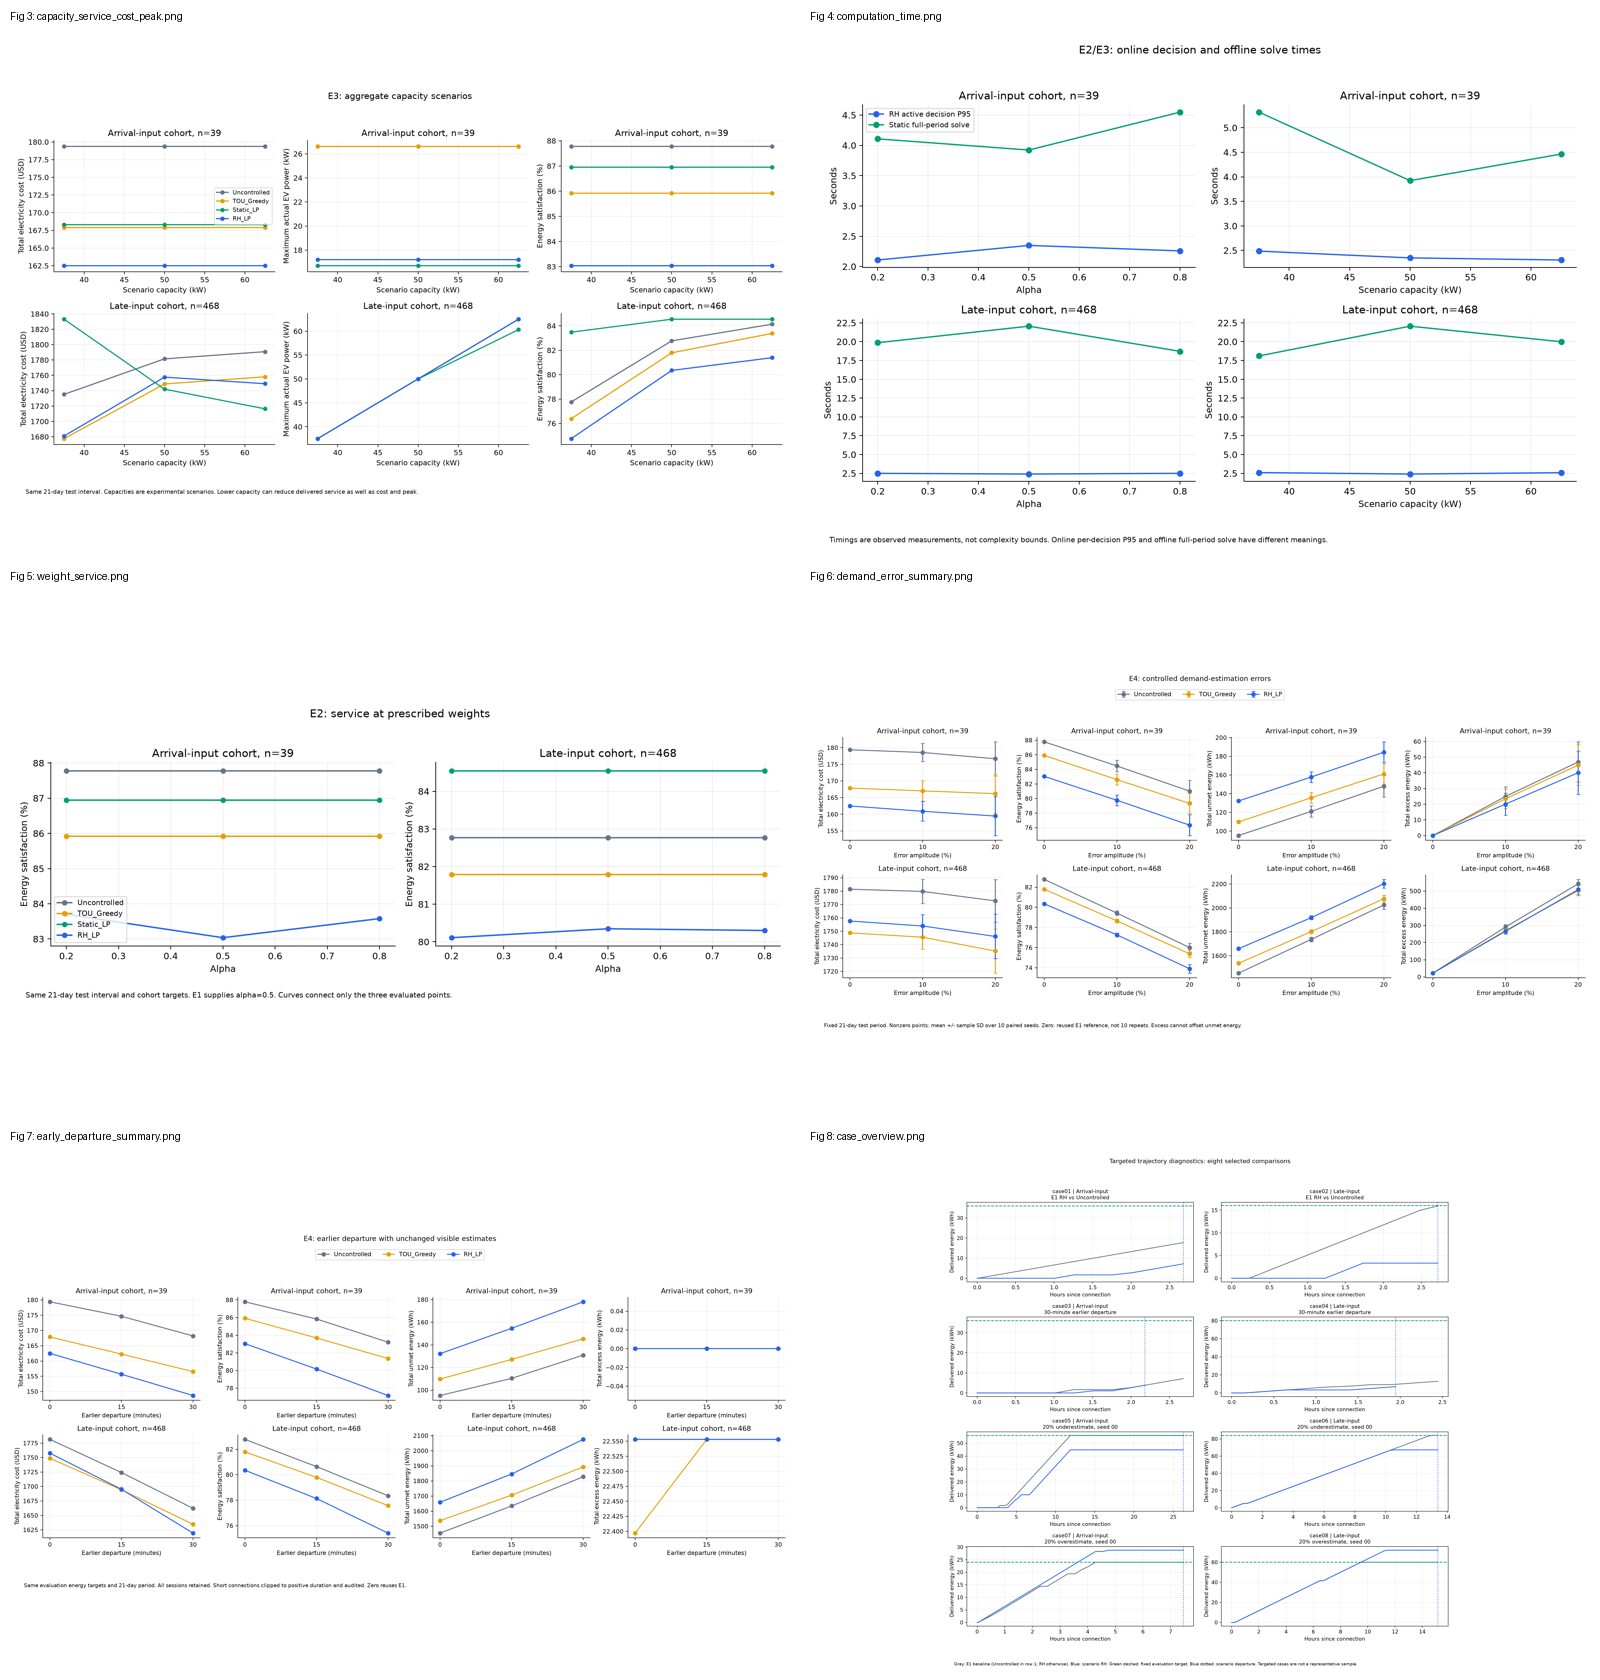

In [4]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import importlib.metadata as metadata
import json
import re
import shutil
import sys
import pandas as pd
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
LOG = ROOT / "results/logs" / f"stage5_method_review_{STAMP}"
LOG.mkdir(parents=True, exist_ok=False)

def sha(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

report_path = ROOT / "report/report.md"
if sha(report_path) != "d413631419131d215d2baa7e466a82a9ebd1fd9c25e1d41c5e9945cc0128c965":
    raise RuntimeError("报告已发生其他编辑，请先核对，避免覆盖")
result_path = ROOT / "results/stage4_all_comparisons.csv"
if sha(result_path) != "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f":
    raise RuntimeError("正式结果来源发生变化")

df = pd.read_csv(result_path)
e1 = df.loc[df.experiment.eq("E1")].copy()
if len(df) != 172 or len(e1) != 8:
    raise RuntimeError("结果数量异常")

# 当前实现与正式实验冻结指纹分别记录，不把二者默认等同
final = yaml.safe_load((ROOT / "configs/final.yaml").read_text())
source_checks = {}
for rel in (
    "src/baselines.py", "src/rolling_horizon.py",
    "src/optimization_model.py", "src/metrics.py",
    "src/simulator.py", "src/acnsim_adapter.py",
):
    current = sha(ROOT / rel)
    frozen = final["source_and_input_sha256"].get(rel)
    source_checks[rel] = {
        "current_sha256": current,
        "frozen_sha256": frozen,
        "matches_frozen": current == frozen,
    }

report = report_path.read_text(encoding="utf-8")

def change_once(old, new):
    global report
    if report.count(old) != 1:
        raise RuntimeError(f"修订定位异常：{old[:60]}")
    report = report.replace(old, new, 1)

change_once(
    "LP内部两层如何共享剩余求解预算，仍需核对优化核心。",
    "LP核心从输入文件写入后开始累计计时，包含输入校验、建模及求解；"
    "每层调用前以剩余累计预算设置求解器时间上限。"
    "第一层确认最优后才加载解并锁定总缺口，第二层同样须确认最优。"
    "内部计时不含最初输入文件写入及最终报告序列化；"
    "外层控制器另外监控决策预算和子进程运行。"
)
change_once(
    "预计离站检查点目标及不可评价分母须与metrics.py核对。",
    "预计离站检查点使用实验入口显式提供的首次有效预计离站及检查点目标。"
    "指标程序累计检查点之前的实际交付，包括跨检查点分段的部分电量。"
    "检查点早于首次有效输入或所需字段缺失时，记为不可评价；"
    "未完成率分母仅为可评价会话，同时单列不可评价数量。"
    "具体目标提取逻辑仍需核对实验入口。"
)
change_once(
    "具体计时边界和硬件信息待结合源码与运行日志核对。",
    "活跃决策指mode不为empty的记录，耗时来自total_seconds。"
    "RH控制器计时包括状态处理、案例构建、子进程求解、计划校验，"
    "以及触发异常时的错误记录与回退；"
    "计时在最终decision.json写入前结束。"
    "它不等于两层求解器耗时之和，也不是完整仿真运行耗时。"
    "离线求解耗时的外层统计边界及硬件信息仍需核对入口与日志。"
)

# 补充服务质量，不只报告总量
labels = {
    "main_at_arrival": "严格主队列",
    "supplement_after_submission": "晚提交补充队列",
}
fields = [
    ("cohort", "队列"), ("method", "方法"),
    ("expected_checkpoint_evaluable_sessions", "可评价会话"),
    ("expected_checkpoint_excluded_sessions", "排除会话"),
    ("expected_departure_uncompleted_rate", "预计离站未完成率/%"),
    ("max_individual_unmet_kwh", "最大个体缺口/kWh"),
    ("session_satisfaction_P10", "个体满足率P10/%"),
]
lines = [
    "| " + " | ".join(label for _, label in fields) + " |",
    "| " + " | ".join(["---"] * len(fields)) + " |",
]
for _, row in e1.sort_values(["cohort", "method"]).iterrows():
    cells = []
    for key, _ in fields:
        value = row[key]
        if pd.isna(value):
            cell = "NA"
        elif key == "cohort":
            cell = labels[value]
        elif key == "method":
            cell = str(value)
        elif key.endswith("_sessions"):
            cell = str(int(value))
        else:
            scale = 100 if key in {
                "expected_departure_uncompleted_rate",
                "session_satisfaction_P10",
            } else 1
            cell = f"{float(value) * scale:.3f}"
        cells.append(cell)
    lines.append("| " + " | ".join(cells) + " |")

service_section = """
### 6.8 预计离站评价与个体服务

""" + "\n".join(lines) + """

预计离站指标与真实离站指标评价时点不同，不可互相替代。
P10按正评价目标会话的逐车满足率计算，采用NumPy默认分位数规则；
零目标会话不进入该分位数。总缺口最小不表示个体公平。

### 6.9 执行残差与回退

172行结果中的设备、站点与连接违规计数均为零，回退次数均为零，
requires_review均为false。
最大功率残差约1.4211e-14 kW，最大能量残差约5.3291e-15 kWh，
均处于数值容差内。细小正残差不记为真实越限。
结果行复用了部分输入和参考，不把这些行作为独立重复检验。
上述检查仅覆盖聚合设备、容量及连接范围，不包含原网络支路与相位可行性。

"""
change_once("## 7 局限与结论", service_section + "## 7 局限与结论")

# 补齐相关工作，并限定本项目与文献的关系
change_once(
    "相关工作仍需补充滚动优化与服务约束文献，并明确与本文方法的关系。",
    "ACN框架研究采用凸优化与模型预测控制进行自适应调度，"
    "并讨论三相不平衡、非理想电池行为及离散控制等实际问题[3]。"
    "本文采用滚动优化这一思路，但研究范围限于聚合连续功率模型，"
    "不声称复现该框架的完整工程约束或文献中的性能。"
    "本文的比较重点是可见信息、实际服务及费用—峰值权衡，"
    "通过双层LP和统一历史重放保留服务下降与无优势的结果。"
)
ref_start = report.index("## 参考文献")
report = report[:ref_start] + """## 参考文献

[1] Lee, Z. J., Li, T., and Low, S. H.
ACN-Data: Analysis and Applications of an Open EV Charging Dataset.
Proceedings of ACM e-Energy, 2019, pp. 139–149.
https://doi.org/10.1145/3307772.3328313

[2] Lee, Z. J., Johansson, D., and Low, S. H.
ACN-Sim: An Open-Source Simulator for Data-Driven Electric Vehicle Charging Research.
IEEE SmartGridComm, 2019, pp. 1–6.
https://doi.org/10.1109/SmartGridComm.2019.8909765

[3] Lee, Z. J., et al.
Adaptive Charging Networks: A Framework for Smart Electric Vehicle Charging.
arXiv:2012.02636, 2020（本文引用该预印本版本）.
https://arxiv.org/abs/2012.02636

资料核查日期：2026-11-16。
"""

# 加入已归档的其余图；避开被最终版本替代的旧权重图
sens = (
    "results/logs/stage4_sensitivity_20261112T124051538161Z/"
    "summary_20261113T083157781711Z/"
)
robust = (
    "results/logs/stage4_robustness_20261113T090451907487Z/"
    "summary_20261114T121318982512Z/"
)
cases = (
    "results/logs/stage4_robustness_20261113T090451907487Z/"
    "case_audit_20261114T122830521605Z/"
)
extra_figures = [
    (sens + "capacity_service_cost_peak.png", "容量、服务、费用与峰值"),
    (sens + "computation_time.png", "计算性能；结合第6.2节计时口径解释"),
    (sens + "weight_service.png", "预设权重下的服务水平"),
    (robust + "demand_error_summary.png",
     "需求误差统计；种子波动不作为跨日期置信区间"),
    (robust + "early_departure_summary.png", "提前离站影响"),
    (cases + "case_overview.png", "八个定向比较概览；涉及七个不同会话"),
]
figure_text = "\n"
for index, (rel, caption) in enumerate(extra_figures, start=3):
    if not (ROOT / rel).is_file():
        raise FileNotFoundError(rel)
    figure_text += f"![图{index} {caption}](../{rel})\n\n图{index} {caption}。\n\n"
change_once(
    "### 6.8 预计离站评价与个体服务",
    figure_text + "### 6.8 预计离站评价与个体服务"
)

mismatches = [p for p, item in source_checks.items()
              if not item["matches_frozen"]]
if mismatches:
    report += (
        "\n## 当前源码与冻结版本核对提示\n\n"
        "以下当前文件与E1冻结指纹不同，须核查变更来源后才能将"
        "当前源码核对结论直接关联至正式实验：\n\n"
        + "\n".join("- " + p for p in mismatches) + "\n"
    )

# 检查报告中的本地Markdown链接，不联网
missing_links = []
for target in re.findall(r"\]\(([^)]+)\)", report):
    if "://" not in target and not target.startswith("#"):
        if not (report_path.parent / target).resolve().exists():
            missing_links.append(target)
if missing_links:
    raise RuntimeError(f"报告引用文件缺失：{missing_links}")

shutil.copy2(report_path, LOG / "report_before.md")
report_path.write_text(report, encoding="utf-8")
service_path = ROOT / "report/tables/E1_individual_checkpoint_service.csv"
e1[[key for key, _ in fields]].to_csv(service_path, index=False)

record = {
    "status": "method_metrics_revised_reproduction_pending",
    "report_sha256": sha(report_path),
    "service_table_sha256": sha(service_path),
    "source_checks": source_checks,
    "missing_report_links": missing_links,
    "added_figures": [rel for rel, _ in extra_figures],
    "pending": [
        "核对实验入口的检查点目标、离线计时及硬件记录",
        "检查报告图表最终显示效果",
        "整理并验证独立复现入口和干净环境",
    ],
}
(LOG / "verification.json").write_text(
    json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("=== 方法与指标修订记录 ===")
print(json.dumps(record, ensure_ascii=False, indent=2))
print("证据目录：", LOG.relative_to(ROOT))

# 环境只读盘点，不安装、不运行实验
print("\n=== 当前环境 ===")
print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
for name in ("pandas", "numpy", "pyomo", "highspy", "acnportal",
             "matplotlib", "PyYAML", "setuptools"):
    try:
        print(name, metadata.version(name))
    except metadata.PackageNotFoundError:
        print(name, "MISSING")

print("\n=== requirements固定版本检查 ===")
req = ROOT / "requirements.txt"
pin_pattern = re.compile(
    r"^[A-Za-z0-9_.-]+(?:\[[A-Za-z0-9_,.-]+\])?==[A-Za-z0-9_.+!-]+$"
)
if req.is_file():
    for n, raw in enumerate(req.read_text(encoding="utf-8-sig").splitlines(), 1):
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        # 非固定版本行不逐字输出，避免意外显示私有来源信息
        print(line if pin_pattern.fullmatch(line)
              else f"第{n}行：非标准固定版本行，待单独核查")
else:
    print("MISSING")

# 读取确切入口和评价目标构造，不执行这些程序
print("\n=== 入口结构与关键片段 ===")
for rel in (
    "experiments/run_all.py",
    "experiments/run_test_evaluation.py",
    "experiments/run_static.py",
    "experiments/compare_results.py",
):
    text = (ROOT / rel).read_text(encoding="utf-8-sig")
    tree = ast.parse(text)
    lines = text.splitlines()
    print(f"\n--- {rel} ---")
    print("函数：", [
        node.name for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ])
    print("命令行参数：")
    for node in ast.walk(tree):
        if (isinstance(node, ast.Call)
                and isinstance(node.func, ast.Attribute)
                and node.func.attr == "add_argument"):
            print(ast.get_source_segment(text, node))

    selected = set()
    needles = (
        "expected_checkpoint_target_kwh", "first_expected_departure",
        "offline_solve_wall_seconds", "platform.", "cpu_count",
        'if __name__', "ROOT =", "argparse.",
    )
    for i, line in enumerate(lines):
        if any(word in line for word in needles):
            selected.update(range(max(0, i - 8), min(len(lines), i + 13)))
    previous = -2
    for i in sorted(selected):
        if i != previous + 1:
            print("...")
        print(f"{i+1}: {lines[i]}")
        previous = i

# 读取小例子的现有调用方式，为干净环境演示准备入口
for rel in ("tests/test_static_lp.py", "tests/test_rolling_horizon.py"):
    print(f"\n=== BEGIN {rel} ===")
    print((ROOT / rel).read_text(encoding="utf-8-sig"))
    print(f"=== END {rel} ===")

# 把六张待检查图拼成一张预览，不改变原图
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

width, height = 800, 560
sheet = Image.new("RGB", (width * 2, height * 3), "white")
draw = ImageDraw.Draw(sheet)
for i, (rel, _) in enumerate(extra_figures):
    x, y = (i % 2) * width, (i // 2) * height
    with Image.open(ROOT / rel) as original:
        thumb = ImageOps.contain(original.convert("RGB"), (width - 20, height - 45))
        sheet.paste(thumb, (
            x + (width - thumb.width) // 2,
            y + 35 + (height - 45 - thumb.height) // 2,
        ))
    draw.text((x + 10, y + 10), f"Fig {i+3}: {Path(rel).name}", fill="black")
preview = LOG / "report_figures_preview.png"
sheet.save(preview)
print("\n图表预览：", preview.relative_to(ROOT))
display(sheet)

In [5]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from packaging.requirements import Requirement
import hashlib
import json
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
JOB = ROOT / "results/logs" / f"stage5_clean_reproduction_{STAMP}"
JOB.mkdir(parents=True, exist_ok=False)

# 保留原requirements；将本机来源改写为已安装版本的精确固定
pins, normalized = {}, []
for n, raw in enumerate(
    (ROOT / "requirements.txt").read_text(encoding="utf-8-sig").splitlines(), 1
):
    line = raw.strip()
    if not line or line.startswith("#"):
        continue
    req = Requirement(line)
    installed = metadata.version(req.name)
    if req.specifier and not req.specifier.contains(installed, prereleases=True):
        raise RuntimeError(f"清单与安装版本不一致：{req.name}")
    name = req.name.lower().replace("_", "-")
    pins[name] = f"{req.name}=={installed}"
    if req.url:
        normalized.append({"line": n, "package": req.name,
                           "replacement_version": installed})

# ACNPortal兼容性所需；原清单未列入
pins["setuptools"] = "setuptools==80.9.0"
if metadata.version("setuptools") != "80.9.0":
    raise RuntimeError("setuptools版本与已验收环境不一致")

lock = ROOT / "requirements.reproduce.txt"
if lock.exists():
    (JOB / "requirements.reproduce.before.txt").write_bytes(lock.read_bytes())
lock.write_text("\n".join(pins[k] for k in sorted(pins)) + "\n", encoding="utf-8")
(JOB / "dependency_normalization.json").write_text(
    json.dumps({
        "original_requirements_sha256": hashlib.sha256(
            (ROOT / "requirements.txt").read_bytes()).hexdigest(),
        "normalized_direct_references": normalized,
        "added_compatibility_pin": "setuptools==80.9.0",
        "original_requirements_modified": False,
    }, ensure_ascii=False, indent=2), encoding="utf-8"
)

SOURCE = r'''
"""Independent clean-environment smoke and frozen-summary reproduction."""
from pathlib import Path
import argparse
import hashlib
import json
import os
import shutil
import subprocess
import sys
import time
import traceback
import venv

ROOT = Path(__file__).resolve().parents[1]

def digest(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def clean_env():
    env = os.environ.copy()
    for key in ("PYTHONPATH", "PYTHONHOME", "PYTHONOPTIMIZE",
                "PIP_USER", "PIP_TARGET", "PIP_PREFIX"):
        env.pop(key, None)
    env["PYTHONNOUSERSITE"] = "1"
    env["MPLBACKEND"] = "Agg"
    return env

def run(command, cwd, log, timeout):
    with log.open("w", encoding="utf-8") as stream:
        result = subprocess.run(
            [str(v) for v in command], cwd=cwd, env=clean_env(),
            stdout=stream, stderr=subprocess.STDOUT, timeout=timeout)
    if result.returncode:
        raise RuntimeError(
            f"Child exit {result.returncode}; inspect {log}")

def worker(out):
    import pandas as pd
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from pandas.testing import assert_frame_equal

    out.mkdir(parents=True, exist_ok=False)
    if sys.prefix == sys.base_prefix:
        raise RuntimeError("Worker is not running in a virtual environment")
    cfg = Path(sys.prefix) / "pyvenv.cfg"
    if "include-system-site-packages = false" not in cfg.read_text().lower():
        raise RuntimeError("Environment permits inherited system packages")

    run([sys.executable, ROOT / "tests/test_static_lp.py",
         "--output", out / "static_cases"],
        ROOT, out / "static.stdout.txt", 600)
    static = json.loads(
        (out / "static_cases/validation_summary.json").read_text())
    if static["status"] != "passed" or (
        static["passed"], static["total"]) != (16, 16):
        raise RuntimeError("Static synthetic validation did not pass 16/16")

    run([sys.executable, ROOT / "tests/test_rolling_horizon.py",
         out / "rolling.json"],
        ROOT, out / "rolling.stdout.txt", 600)
    rolling = json.loads((out / "rolling.json").read_text())
    if rolling["status"] != "passed" or rolling["check_count"] != 17:
        raise RuntimeError("RH synthetic validation did not pass 17/17")

    source = ROOT / "results/stage4_all_comparisons.csv"
    wanted = "1096d28710fe444a0e1f7003bcc5cb6c67878b6983dbab2d1f8fbdecef405e8f"
    if digest(source) != wanted:
        raise RuntimeError("Frozen results fingerprint mismatch")
    df = pd.read_csv(source)
    if len(df) != 172:
        raise RuntimeError("Unexpected result count")
    e1 = df.loc[df.experiment.eq("E1")].copy()
    reference = e1.loc[e1.method.ne("Static_LP"), [
        "cohort", "method", "cost_USD", "unmet_kwh", "energy_satisfaction"
    ]].rename(columns={
        "cost_USD": "reference_cost_USD",
        "unmet_kwh": "reference_unmet_kwh",
        "energy_satisfaction": "reference_satisfaction",
    })
    keys = ["cohort", "method"]
    group = keys + ["amplitude"]
    noise = df.loc[
        df.experiment.eq("E4") &
        pd.to_numeric(df.amplitude, errors="coerce").gt(0)
    ].copy()
    if len(noise) != 120 or noise.duplicated(group + ["seed"]).any():
        raise RuntimeError("Invalid seed grid")
    stats = noise.groupby(group, as_index=False).agg(
        seed_count=("seed", "nunique"),
        cost_mean_USD=("cost_USD", "mean"),
        unmet_mean_kwh=("unmet_kwh", "mean"),
        excess_mean_kwh=("excess_kwh", "mean"),
        satisfaction_mean=("energy_satisfaction", "mean"),
        satisfaction_SD=("energy_satisfaction", "std"),
    )
    if len(stats) != 12 or not stats.seed_count.eq(10).all():
        raise RuntimeError("Expected twelve groups of ten seeds")
    stats = stats.merge(reference, on=keys, validate="many_to_one")
    stats["satisfaction_mean_pct"] = stats.satisfaction_mean * 100
    stats["satisfaction_SD_pp"] = stats.satisfaction_SD * 100
    stats["delta_satisfaction_pp"] = (
        stats.satisfaction_mean - stats.reference_satisfaction) * 100
    stats["delta_unmet_kwh"] = (
        stats.unmet_mean_kwh - stats.reference_unmet_kwh)

    early = df.loc[
        df.experiment.eq("E4") &
        pd.to_numeric(df.advance_minutes, errors="coerce").gt(0)
    ].copy().merge(reference, on=keys, validate="many_to_one")
    early["delta_satisfaction_pp"] = (
        early.energy_satisfaction - early.reference_satisfaction) * 100
    early["delta_unmet_kwh"] = early.unmet_kwh - early.reference_unmet_kwh

    tables = {
        "sensitivity_all_methods.csv":
            df.loc[df.experiment.isin(["E1", "E2", "E3"])].copy(),
        "demand_error_seed_statistics.csv": stats,
        "early_departure_comparisons.csv": early,
    }
    table_checks = {}
    for name, frame in tables.items():
        target = out / name
        frame.to_csv(target, index=False)
        # 比较重新读入的数值，避免CSV末位格式差异造成误报
        actual = pd.read_csv(target)
        expected = pd.read_csv(ROOT / "report/tables" / name)
        assert_frame_equal(
            actual, expected, check_dtype=False, check_exact=False,
            rtol=1e-10, atol=1e-8)
        table_checks[name] = {
            "status": "passed", "rows": len(frame), "sha256": digest(target)}

    # 独立汇总图：验证干净环境能从冻结结果生成图表
    methods = ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"]
    cohorts = ["main_at_arrival", "supplement_after_submission"]
    colors = ["#64748b", "#f59e0b", "#059669", "#2563eb"]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
    for i, cohort in enumerate(cohorts):
        part = e1.loc[e1.cohort.eq(cohort)].set_index("method").loc[methods]
        for j, (metric, label, scale) in enumerate([
            ("cost_USD", "Cost (USD)", 1),
            ("energy_satisfaction", "Energy satisfaction (%)", 100),
            ("max_peak_kW", "Maximum EV power (kW)", 1),
        ]):
            ax = axes[i, j]
            ax.bar(["UC", "TOU", "Static", "RH"], part[metric] * scale,
                   color=colors)
            ax.set_title(cohort.replace("_", " "))
            ax.set_ylabel(label)
            ax.grid(axis="y", alpha=.2)
    fig.suptitle("Frozen E1 summary; Static is an offline reference")
    fig.savefig(out / "E1_summary.png", dpi=180)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for ax, cohort in zip(axes, cohorts):
        for method, color in zip(
            ["Uncontrolled", "TOU_Greedy", "RH_LP"],
            [colors[0], colors[1], colors[3]]
        ):
            part = stats.loc[
                stats.cohort.eq(cohort) & stats.method.eq(method)
            ].sort_values("amplitude")
            base = reference.loc[
                reference.cohort.eq(cohort) & reference.method.eq(method)
            ].iloc[0]
            x = [0] + (part.amplitude * 100).tolist()
            y = [base.reference_satisfaction * 100] + (
                part.satisfaction_mean_pct.tolist())
            error = [0] + part.satisfaction_SD_pp.tolist()
            ax.errorbar(x, y, yerr=error, marker="o",
                        capsize=3, label=method, color=color)
        ax.set_title(cohort.replace("_", " "))
        ax.set_xlabel("Controlled error amplitude (%)")
        ax.set_ylabel("Energy satisfaction (%)")
        ax.grid(alpha=.2)
    axes[0].legend(fontsize=8)
    fig.suptitle("Mean +/- sample SD over 10 seeds; zero reuses E1")
    fig.savefig(out / "demand_error_summary.png", dpi=180)
    plt.close(fig)

    result = {
        "status": "passed",
        "scope": "clean synthetic static/RH/ACN-Sim and frozen-result summary",
        "static_checks": static["passed"],
        "rolling_checks": rolling["check_count"],
        "table_checks": table_checks,
        "generated_figures": ["E1_summary.png", "demand_error_summary.png"],
        "python": sys.version,
        "system_site_packages": False,
        "full_formal_experiments_rerun": False,
        "raw_data_preprocessing_rerun": False,
    }
    (out / "verification.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

def supervisor(out):
    out.mkdir(parents=True, exist_ok=True)
    if (out / "status.json").exists():
        raise FileExistsError("Use a new output directory")
    started = time.perf_counter()

    def state(status, stage, **extra):
        value = {
            "status": status, "stage": stage,
            "elapsed_seconds": time.perf_counter() - started, **extra}
        temporary = out / "status.tmp"
        temporary.write_text(
            json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
        temporary.replace(out / "status.json")

    try:
        state("running", "copying_workspace")
        snapshot = out / "workspace"
        snapshot.mkdir()
        ignore = shutil.ignore_patterns("__pycache__", "*.pyc")
        for folder in ("src", "configs", "tests"):
            shutil.copytree(ROOT / folder, snapshot / folder, ignore=ignore)
        files = [
            "experiments/reproduce_stage5.py", "requirements.reproduce.txt",
            "results/stage4_all_comparisons.csv",
            "report/tables/sensitivity_all_methods.csv",
            "report/tables/demand_error_seed_statistics.csv",
            "report/tables/early_departure_comparisons.csv",
        ]
        snapshots = {}
        for rel in files:
            target = snapshot / rel
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(ROOT / rel, target)
            snapshots[rel] = digest(target)
        (out / "snapshot_files.json").write_text(
            json.dumps(snapshots, indent=2), encoding="utf-8")

        envdir = ROOT / ".envs" / ("reproduce-" + out.name)
        if envdir.exists():
            raise FileExistsError(envdir)
        state("running", "creating_virtual_environment")
        venv.EnvBuilder(with_pip=True, system_site_packages=False).create(envdir)
        python = envdir / "bin/python"

        state("running", "installing_dependencies")
        run([python, "-m", "pip", "--disable-pip-version-check",
             "install", "-r", snapshot / "requirements.reproduce.txt"],
            snapshot, out / "install.log", 1800)
        run([python, "-m", "pip", "check"],
            snapshot, out / "pip_check.log", 120)

        state("running", "running_synthetic_checks_and_summary")
        evidence = snapshot / "results/reproduction"
        run([python, snapshot / "experiments/reproduce_stage5.py",
             "--worker", "--output", evidence],
            snapshot, out / "worker.log", 1800)
        result = json.loads((evidence / "verification.json").read_text())
        if result.get("status") != "passed":
            raise RuntimeError("Worker did not pass")
        state("passed", "complete", evidence=str(evidence),
              environment=str(envdir), result=result)
    except Exception as exc:
        (out / "error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        state("failed", "stopped", error=repr(exc))
        raise

if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--output", required=True)
    parser.add_argument("--worker", action="store_true")
    args = parser.parse_args()
    output = Path(args.output).resolve()
    if args.worker:
        worker(output)
    else:
        supervisor(output)
'''
# 写入前做语法检查；已存在入口先备份
compile(SOURCE, "reproduce_stage5.py", "exec")
script = ROOT / "experiments/reproduce_stage5.py"
if script.exists():
    (JOB / "reproduce_stage5.before.py").write_bytes(script.read_bytes())
script.write_text(SOURCE, encoding="utf-8")

with (JOB / "supervisor.log").open("w", encoding="utf-8") as stream:
    process = subprocess.Popen(
        [sys.executable, str(script), "--output", str(JOB)],
        cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT,
        start_new_session=True,
    )
(ROOT / "report/stage5_reproduction_job.json").write_text(
    json.dumps({"directory": str(JOB), "pid": process.pid},
               ensure_ascii=False, indent=2), encoding="utf-8"
)

print("=== 干净环境验证已启动 ===")
print("目录：", JOB)
print("PID：", process.pid)
print("本机来源规范化：", normalized)
print("原requirements.txt保持不变；尚无验收结果。")

# 补读上轮未完整显示的评价目标和离线计时构造
text = (ROOT / "experiments/run_test_evaluation.py").read_text(encoding="utf-8")
lines = text.splitlines()
print("\n=== 正式入口：评价目标构造 ===")
for i in range(185, min(241, len(lines))):
    print(f"{i+1}: {lines[i]}")
print("\n=== 正式入口：离线计时 ===")
selected = set()
for i, line in enumerate(lines):
    if "offline_seconds =" in line:
        selected.update(range(max(0, i - 15), min(len(lines), i + 6)))
for i in sorted(selected):
    print(f"{i+1}: {lines[i]}")

=== 干净环境验证已启动 ===
目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage5_clean_reproduction_20261116T074902798172Z
PID： 619052
本机来源规范化： [{'line': 27, 'package': 'packaging', 'replacement_version': '26.3'}]
原requirements.txt保持不变；尚无验收结果。

=== 正式入口：评价目标构造 ===
186:             })
187:     return pd.DataFrame(station_rows), pd.DataFrame(
188:         vehicle_rows,
189:         columns=["sessionID", "start", "end", "actual_kw", "energy_kwh"])
190: 
191: for cohort, expected_count in [
192:     ("main_at_arrival", 39), ("supplement_after_submission", 468),
193: ]:
194:     selected = sessions[
195:         (sessions["split"] == args.split) &
196:         (sessions["cohort"] == cohort) &
197:         (sessions["connectionTime"] >= start) &
198:         (sessions["connectionTime"] < arrival_end)
199:     ].copy()
200:     check(cohort + ": fixed shared selection", len(selected) == expected_count)
201:     ids = set(selected["sessionID"])
202:     ev = events[events["

In [10]:
from pathlib import Path
import json
import re

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
job = json.loads(
    (ROOT / "report/stage5_reproduction_job.json").read_text(encoding="utf-8")
)
folder = Path(job["directory"])
status = folder / "status.json"
if status.exists():
    result = json.loads(status.read_text(encoding="utf-8"))
    print(json.dumps(result, ensure_ascii=False, indent=2))
    if result["status"] == "failed":
        for name in ("error.txt", "install.log", "pip_check.log", "worker.log"):
            path = folder / name
            if path.exists():
                tail = "\n".join(
                    path.read_text(encoding="utf-8", errors="replace")
                    .splitlines()[-25:]
                )
                print(f"\n=== {name} ===")
                print(re.sub(r"https?://\S+", "<URL omitted>", tail))
else:
    print("验证进程正在初始化。")

{
  "status": "passed",
  "stage": "complete",
  "elapsed_seconds": 166.0916351461783,
  "evidence": "/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage5_clean_reproduction_20261116T074902798172Z/workspace/results/reproduction",
  "environment": "/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/reproduce-stage5_clean_reproduction_20261116T074902798172Z",
  "result": {
    "status": "passed",
    "scope": "clean synthetic static/RH/ACN-Sim and frozen-result summary",
    "static_checks": 16,
    "rolling_checks": 17,
    "table_checks": {
      "sensitivity_all_methods.csv": {
        "status": "passed",
        "rows": 40,
        "sha256": "c29ff6e2256ad7588d5d52307996620e52953648d44f043382701fa0ac80541e"
      },
      "demand_error_seed_statistics.csv": {
        "status": "passed",
        "rows": 12,
        "sha256": "ff9a26018952f9abdcf2c018d0912dbc7cbdae7d73c091297e4d5576dd73b80f"
      },
      "early_departure_comparisons.csv": {
   

=== 交付文档写入 ===
{
  "report/report.md": "bf1c8e2734511c6a8477c7c0f8f6202e7acdf6461391abf0929bf840dcddd419",
  "README.md": "87d8a25cec8e8de368cf2c24d4f736209ca4fa01432424dcac7f806f38b77436",
  "report/stage5_reproduction.md": "4ade58a7ea10454f283f8445bdf51137e606273a7731449988aa60c33b967106"
}
证据目录： results/logs/stage5_delivery_docs_20261116T080428319783Z

=== 正式入口：评价目标构造 ===
151:     if not common:
152:         return None
153:     keys = {key for key in old_power.keys() | new_power.keys()
154:             if key[1] in common}
155:     return sum(abs(new_power.get(key, 0) - old_power.get(key, 0)) for key in keys)
156: 
157: def tou_bundle(result):
158:     labels = [t.isoformat() for t in result["slots"]]
159:     powers = {
160:         (sid, labels[j]): float(power)
161:         for sid, values in result["plan_kw"].items()
162:         for j, power in enumerate(values) if power > 0
163:     }
164:     return set(labels), powers
165: 
166: def csv_bundle(path):
167:     frame = pd.rea

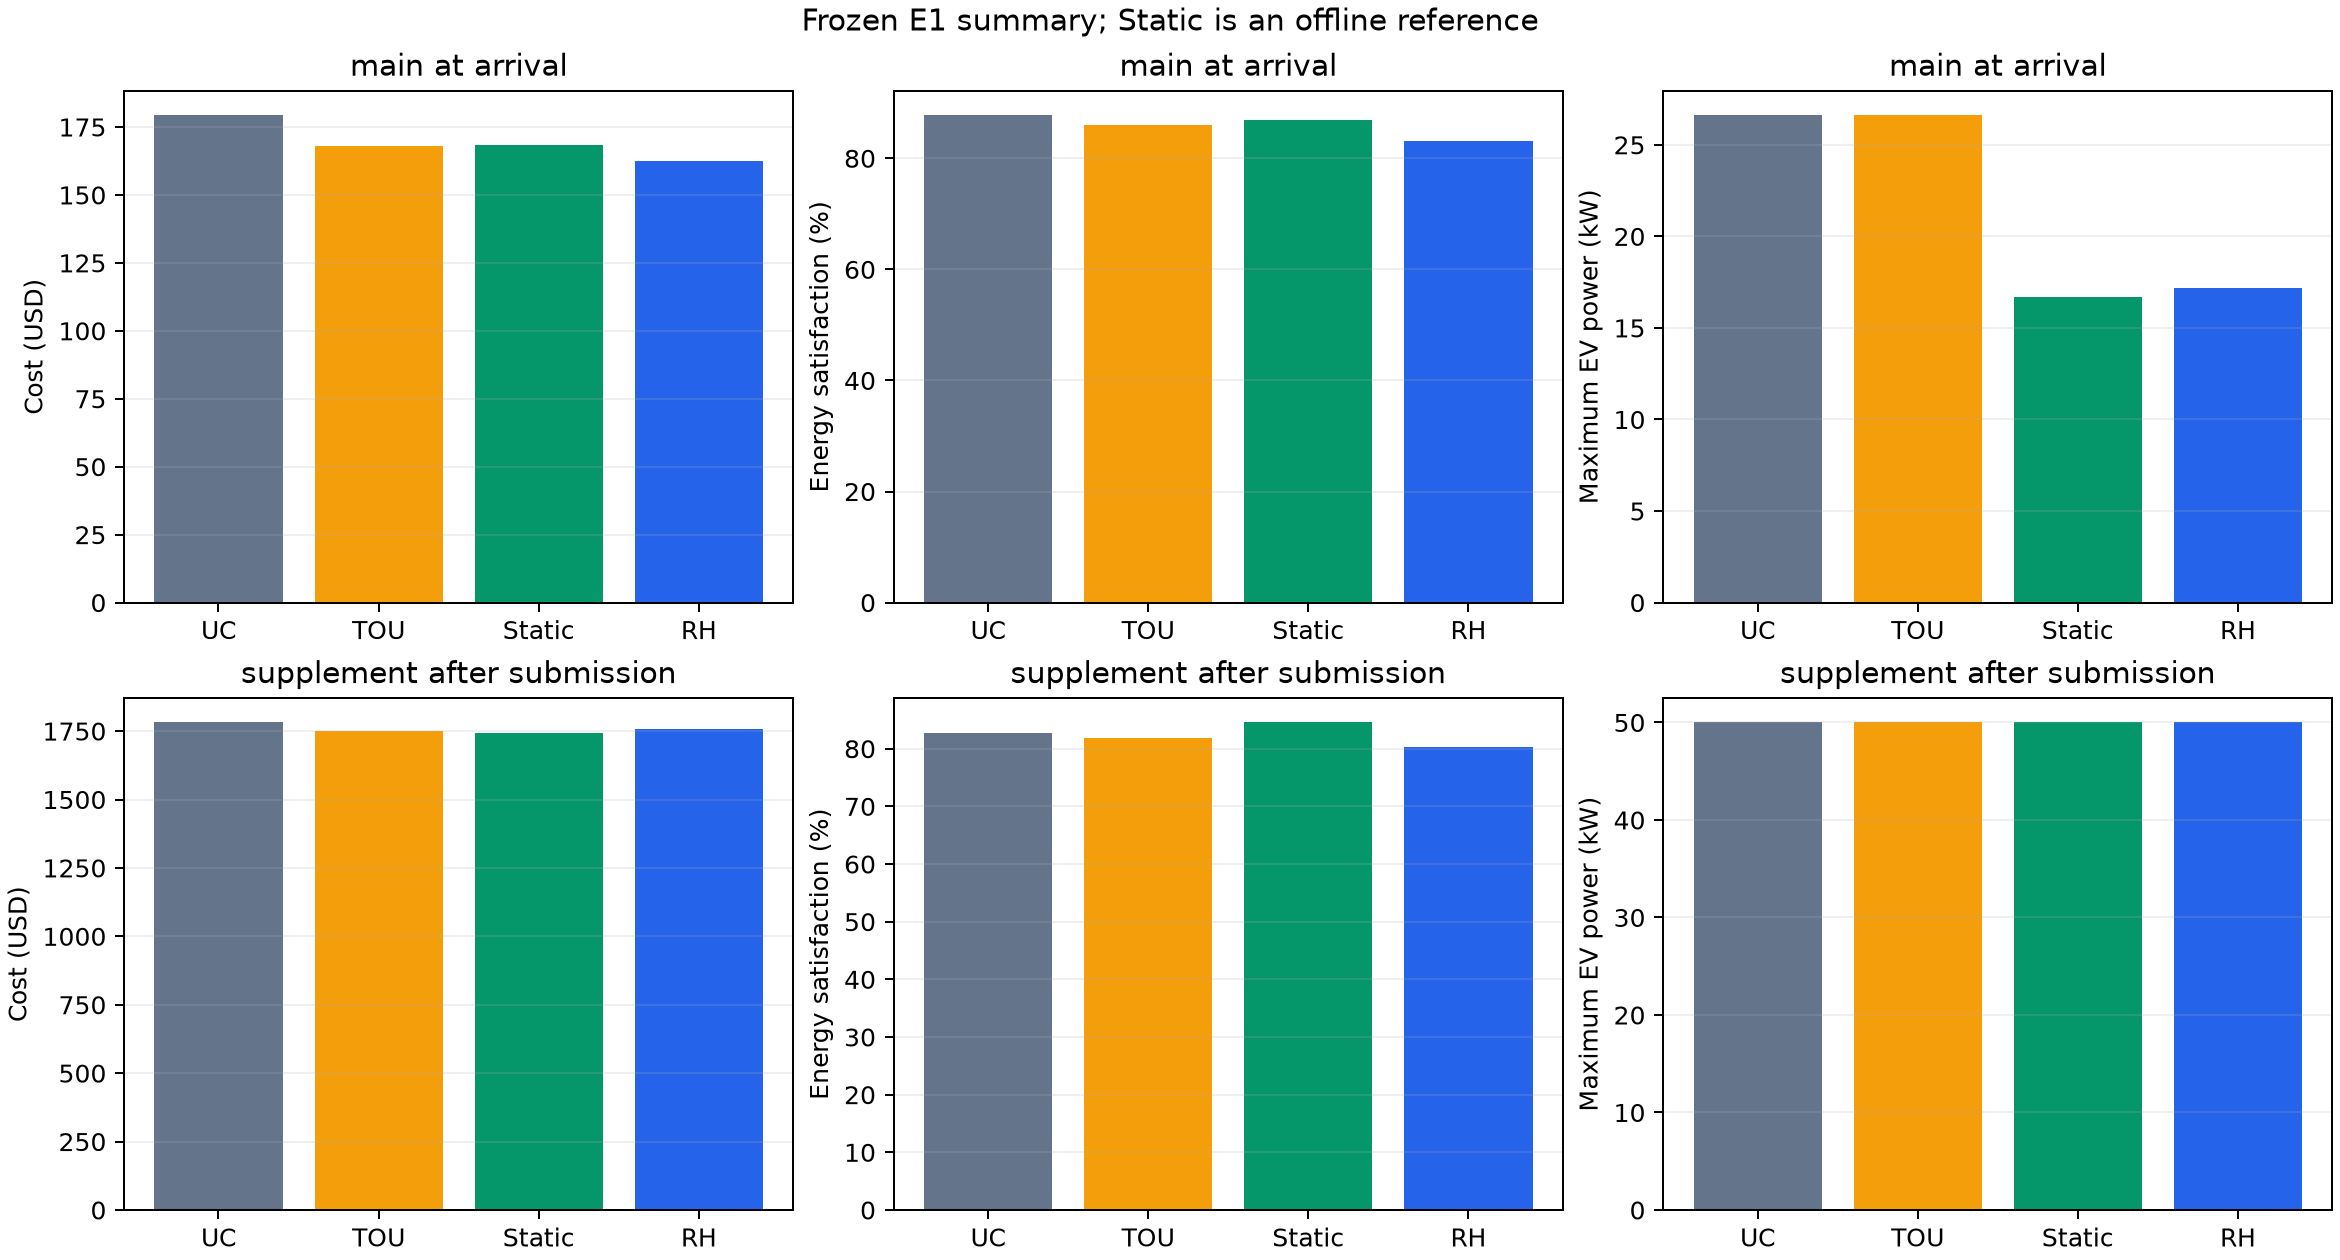

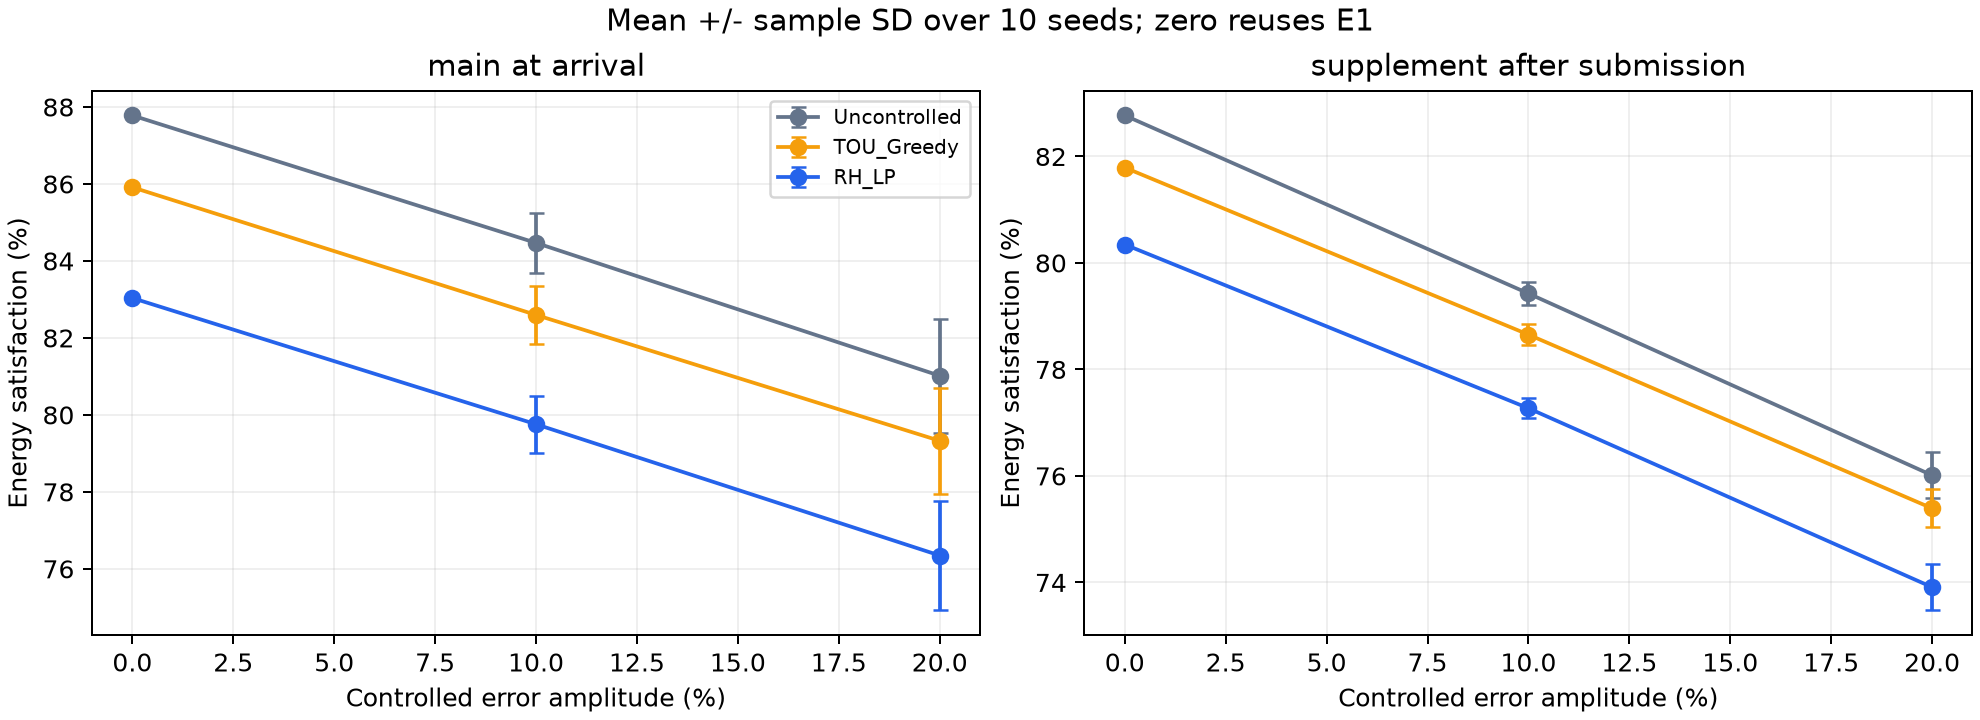

In [11]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
LOG = ROOT / "results/logs" / f"stage5_delivery_docs_{STAMP}"
LOG.mkdir(parents=True, exist_ok=False)

def sha(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

job = json.loads(
    (ROOT / "report/stage5_reproduction_job.json").read_text(encoding="utf-8")
)
folder = Path(job["directory"])
status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
if status["status"] != "passed":
    raise RuntimeError("干净环境验证尚未通过")

evidence = Path(status["evidence"])
verification = json.loads(
    (evidence / "verification.json").read_text(encoding="utf-8")
)
if (verification["static_checks"], verification["rolling_checks"]) != (16, 17):
    raise RuntimeError("验证检查数量异常")

for name, check in verification["table_checks"].items():
    original = ROOT / "report/tables" / name
    reproduced = evidence / name
    if not (
        check["status"] == "passed"
        and sha(original) == sha(reproduced) == check["sha256"]
    ):
        raise RuntimeError(f"汇总表证据不一致：{name}")

report_path = ROOT / "report/report.md"
if sha(report_path) != "fe7afc35f1702238e584de93df6bdc8195bdf92864b5fc8ce3e51c37466585db":
    raise RuntimeError("报告已发生其他编辑，请先核对")

relative_evidence = evidence.relative_to(ROOT).as_posix()
relative_job = folder.relative_to(ROOT).as_posix()
elapsed = status["elapsed_seconds"]

chapter = f"""## 8 复现与交付

### 8.1 环境和独立入口

使用Python 3.11.18。
原requirements.txt保留为正式实验历史清单；
requirements.reproduce.txt为本次验证使用的可移植版本清单，
将本机直接来源规范化为已安装包的精确版本，并补入
ACNPortal兼容性所需的setuptools==80.9.0。
依赖规范化记录保存在本次验证目录。

独立入口为experiments/reproduce_stage5.py。
入口创建不继承系统site-packages的新虚拟环境，
安装固定依赖并执行pip check，然后在项目副本中运行检查和汇总。
副本不依赖Notebook内存，旧静态检查写出的model_validation.md
仅影响副本，不覆盖原项目验收材料。

### 8.2 验证结果

本次总耗时{elapsed:.3f}秒，最终status=passed。
静态合成检查16/16通过，RH合成检查17/17通过，
后者包含真实LP决策与ACN-Sim闭环反馈检查。

三份重新生成的表分别为40行四方法敏感性结果、
12行十种子需求误差统计及12行提前离站比较。
三份表与报告已有表的SHA-256全部一致。
另生成E1_summary.png和demand_error_summary.png，
验证新环境能从冻结结果生成汇总图。

本次没有重新下载数据、重跑原始数据预处理或重跑27个完整正式运行。
因此，验证结论限于干净环境中的小例子、闭环关键路径、
冻结结果统计及图表生成，不称为全量正式实验重跑。

### 8.3 证据与指南

- [验证状态](../{relative_job}/status.json)
- [独立验证记录](../{relative_evidence}/verification.json)
- [汇总图：主实验](../{relative_evidence}/E1_summary.png)
- [汇总图：需求误差](../{relative_evidence}/demand_error_summary.png)
- [复现指南](../README.md)

完整实验入口、数据版本与最终成果索引由README及交付索引说明。
"""

report = report_path.read_text(encoding="utf-8")
start = report.index("## 8 复现与交付")
end = report.index("## 参考文献", start)
report = report[:start] + chapter + "\n" + report[end:]

frozen_hash = sha(ROOT / "configs/final.yaml")
readme = f"""# 电动汽车滚动时域充电优化

Caltech单站历史会话重放，比较Uncontrolled、TOU Greedy、
完整信息Static LP与RH-LP。使用聚合连续功率、实验TOU和容量情景；
服务、费用与峰值联合评价。

## 阅读入口

- 课程报告：report/report.md
- 数据与假设：report/data_profile.md、report/assumptions.md
- 数学规格：report/model.md（保留阶段二历史状态，正式参数以冻结配置为准）
- 正式参数：configs/final.yaml、configs/normalization.yaml
- 最终发现：report/findings.md
- 全部结果：results/stage4_all_comparisons.csv
- 来源清单：results/run_manifest.csv
- 阶段四索引：report/stage4_artifact_index.csv

正式结果172行，对应27个运行中的方法／队列／情景组合，
不是172个独立运行。两个队列分别评价。

## 一条命令验证关键路径

在项目根目录使用Python 3.11运行，先确认python --version。
脚本会自行创建新环境，无须预先激活原项目环境。
安装依赖需要可用的软件包来源。

    python experiments/reproduce_stage5.py --output results/logs/reproduction_run_001

每次使用新的输出目录名。
该命令依次完成：复制必要文件、新建隔离环境、安装固定依赖、
pip check、静态16项检查、RH17项检查、汇总表重算比对与绘图。

状态文件位于指定输出目录的status.json。
成功时status=passed、stage=complete；
数值检查证据和图片位于其workspace/results/reproduction/。
失败时检查error.txt、install.log、pip_check.log和worker.log。

实测总耗时{elapsed:.3f}秒；其他机器的安装与运行时间可能不同。
程序使用requirements.reproduce.txt；原requirements.txt保持不变。
该验证不会重跑全量正式实验或原始数据预处理。

## 已通过的干净环境记录

- Python：3.11.18，不继承系统site-packages。
- 静态检查：16/16。
- RH检查：17/17，包含ACN-Sim闭环。
- 三份重算表：40／12／12行，与报告表文件哈希全部一致。
- 新图：E1_summary.png、demand_error_summary.png。
- 证据：{relative_job}/status.json。
- 原始数据预处理与全部正式实验：本次未重跑。

## 数据版本

原始快照：
data/raw/caltech_12weeks_20261111T143402Z_9b087d/，
查询条件与哈希见该目录manifest.json。

处理数据：
data/processed/caltech_12weeks_20261111T143402Z_9b087d/。

完整实验需要原项目对应的处理数据、电价、冻结配置与来源文件。
新下载的数据不能自动视为同一快照。
数据来源为ACN-Data；引用与适用范围见课程报告。

## 正式E1重跑入口

以下命令按已核对的正式入口参数编写；
阶段五本次未重新执行该全量命令。
需要完整项目数据，且输出目录必须是新目录。

    python experiments/run_test_evaluation.py results/logs/main_test_replay_001 --split test --alpha 0.5 --capacity-kw 50 --base-hours 24 --static-time-limit 120 --frozen-config-sha256 {frozen_hash}

历史E1约耗时70分钟。
权重／容量新增情景历史约4小时43分钟，
误差与提前离站情景合计历史约20小时22分钟；
时间均为原环境观察值。

E2／E3、E4的确切批处理命令及最终交付清单将在入口核对后补齐。

## 结果解释边界

Static LP拥有完整未来信息，其完整时段可行域与在线实际执行口径不同。
较低费用可能伴随较少交付，不能直接解释为同服务节费。
严格主队列测试仅39条，补充队列468条，测试21天。
实验不包含建筑负荷、原网络支路与相位约束或真实账单核算。
"""

for rel, content in {
    "report/report.md": report,
    "README.md": readme,
}.items():
    target = ROOT / rel
    if target.exists():
        backup = LOG / "before" / rel
        backup.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(target, backup)
    target.write_text(content, encoding="utf-8")

reproduction_record = {
    "status": "passed",
    "scope": verification["scope"],
    "elapsed_seconds": elapsed,
    "evidence_directory": relative_evidence,
    "job_directory": relative_job,
    "static_checks": 16,
    "rolling_checks": 17,
    "tables": verification["table_checks"],
    "full_formal_experiments_rerun": False,
    "raw_data_preprocessing_rerun": False,
    "stage5_overall_accepted": False,
    "pending": [
        "补齐完整批处理命令",
        "完成剩余方法入口核对和报告状态文字清理",
        "最终成果索引与成果包核验",
    ],
}
record_path = ROOT / "report/stage5_reproduction.md"
if record_path.exists():
    shutil.copy2(record_path, LOG / "stage5_reproduction.before.md")
record_path.write_text(
    "# 阶段五干净环境关键路径验证\n\n"
    + "```json\n"
    + json.dumps(reproduction_record, ensure_ascii=False, indent=2)
    + "\n```\n",
    encoding="utf-8"
)
outputs = {
    rel: sha(ROOT / rel)
    for rel in ("report/report.md", "README.md", "report/stage5_reproduction.md")
}
(LOG / "verification.json").write_text(
    json.dumps({"status": "documents_written_not_final_acceptance",
                "output_sha256": outputs},
               ensure_ascii=False, indent=2), encoding="utf-8"
)
print("=== 交付文档写入 ===")
print(json.dumps(outputs, ensure_ascii=False, indent=2))
print("证据目录：", LOG.relative_to(ROOT))

# 补齐此前未返回的入口片段；只读取，不运行
text = (ROOT / "experiments/run_test_evaluation.py").read_text(encoding="utf-8")
lines = text.splitlines()
print("\n=== 正式入口：评价目标构造 ===")
for i in range(150, min(241, len(lines))):
    print(f"{i+1}: {lines[i]}")
print("\n=== 正式入口：离线计时 ===")
selected = set()
for i, line in enumerate(lines):
    if "offline_seconds =" in line:
        selected.update(range(max(0, i - 15), min(len(lines), i + 6)))
for i in sorted(selected):
    print(f"{i+1}: {lines[i]}")

for rel in (
    "experiments/run_sensitivity_batch.py",
    "experiments/run_robustness_batch.py",
):
    print(f"\n=== BEGIN {rel} ===")
    print((ROOT / rel).read_text(encoding="utf-8-sig"))
    print(f"=== END {rel} ===")

print("\n=== 依赖规范化记录 ===")
print((folder / "dependency_normalization.json").read_text(encoding="utf-8"))

# 展示干净环境实际生成的两张新图
from IPython.display import display, Image
for name in ("E1_summary.png", "demand_error_summary.png"):
    display(Image(filename=str(evidence / name), width=1000))

In [12]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import csv
import hashlib
import json
import re
import shutil
import subprocess
import sys
import zipfile
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
LOG = ROOT / "results/logs" / f"stage5_finalization_{STAMP}"
LOG.mkdir(parents=True, exist_ok=False)

def sha(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

expected_docs = {
    "report/report.md":
        "bf1c8e2734511c6a8477c7c0f8f6202e7acdf6461391abf0929bf840dcddd419",
    "README.md":
        "87d8a25cec8e8de368cf2c24d4f736209ca4fa01432424dcac7f806f38b77436",
}
for rel, expected in expected_docs.items():
    if sha(ROOT / rel) != expected:
        raise RuntimeError(f"文档已发生其他编辑，停止覆盖：{rel}")

# 归档前检查：仅读取代码，不执行旧脚本
issues = []
secret_names = {
    "TOKEN", "API_KEY", "ACN_TOKEN", "ACN_API_TOKEN", "PASSWORD", "API_TOKEN"
}
for directory in ("src", "experiments", "tests"):
    for path in sorted((ROOT / directory).rglob("*.py")):
        if "__pycache__" in path.parts:
            continue
        text = path.read_text(encoding="utf-8-sig")
        tree = ast.parse(text, filename=str(path))
        for node in ast.walk(tree):
            if isinstance(node, ast.Constant) and isinstance(node.value, str):
                value = node.value
                if (
                    value.startswith(("/home/", "/Users/"))
                    or re.match(r"^[A-Za-z]:[\\/](Users|Documents and Settings)[\\/]", value)
                ):
                    issues.append({
                        "file": str(path.relative_to(ROOT)),
                        "line": node.lineno, "kind": "absolute_user_path",
                    })
            if isinstance(node, ast.Assign):
                if isinstance(node.value, ast.Constant) and isinstance(node.value.value, str):
                    if node.value.value.strip():
                        for target in node.targets:
                            if isinstance(target, ast.Name) and target.id.upper() in secret_names:
                                issues.append({
                                    "file": str(path.relative_to(ROOT)),
                                    "line": node.lineno,
                                    "kind": "literal_credential_assignment",
                                })
if issues:
    print("=== 归档前需处理的源码位置 ===")
    print(json.dumps(issues, ensure_ascii=False, indent=2))
    raise RuntimeError("先核对上述位置；未生成最终成果包")

# 冻结协议和当前来源必须保持一致
protocols = {
    "configs/final.yaml": None,
    "configs/sensitivity.yaml":
        "7079f7033ae1bfd38d2bbf4a76115cfc1fe002137b779d034b3c4af36d1f23e4",
    "configs/robustness.yaml":
        "5c52d926f1f94598f9f285babd0cacf0365db4b7fc085029f70d7be2618aa5e8",
}
for rel, expected in protocols.items():
    if expected and sha(ROOT / rel) != expected:
        raise RuntimeError(f"冻结协议改变：{rel}")
    document = yaml.safe_load((ROOT / rel).read_text(encoding="utf-8"))
    if document["status"] != "frozen":
        raise RuntimeError(f"协议未冻结：{rel}")
    for source, expected_hash in document["source_and_input_sha256"].items():
        if sha(ROOT / source) != expected_hash:
            raise RuntimeError(f"冻结来源不一致：{rel} -> {source}")

job = json.loads(
    (ROOT / "report/stage5_reproduction_job.json").read_text(encoding="utf-8")
)
job_folder = Path(job["directory"])
status = json.loads((job_folder / "status.json").read_text(encoding="utf-8"))
if status["status"] != "passed":
    raise RuntimeError("干净环境验证未通过")
evidence = Path(status["evidence"])
verification = json.loads((evidence / "verification.json").read_text(encoding="utf-8"))
for name, item in verification["table_checks"].items():
    if sha(ROOT / "report/tables" / name) != sha(evidence / name):
        raise RuntimeError(f"重算表发生变化：{name}")

# 为两个原批处理提供可直接使用的入口；不修改旧批处理和冻结协议
launcher = r'''
"""Run archived frozen batches; does not regenerate or retune protocols."""
from pathlib import Path
import argparse
import hashlib
import subprocess
import sys

ROOT = Path(__file__).resolve().parents[1]
parser = argparse.ArgumentParser()
parser.add_argument("kind", choices=["sensitivity", "robustness"])
parser.add_argument("--output", required=True)
args = parser.parse_args()
choices = {
    "sensitivity": (
        "configs/sensitivity.yaml",
        "7079f7033ae1bfd38d2bbf4a76115cfc1fe002137b779d034b3c4af36d1f23e4",
        "experiments/run_sensitivity_batch.py"),
    "robustness": (
        "configs/robustness.yaml",
        "5c52d926f1f94598f9f285babd0cacf0365db4b7fc085029f70d7be2618aa5e8",
        "experiments/run_robustness_batch.py"),
}
config, expected, entry = choices[args.kind]
config = ROOT / config
with config.open("rb") as stream:
    actual = hashlib.file_digest(stream, "sha256").hexdigest()
if actual != expected:
    raise RuntimeError("Frozen configuration fingerprint mismatch")
out = Path(args.output)
if not out.is_absolute():
    out = ROOT / out
out = out.resolve()
if not out.is_relative_to(ROOT):
    raise ValueError("Output must be inside this project")
out.mkdir(parents=True, exist_ok=False)
completed = subprocess.run(
    [sys.executable, str(ROOT / entry), str(config), expected, str(out)],
    cwd=ROOT)
sys.exit(completed.returncode)
'''
compile(launcher, "run_frozen_batch.py", "exec")
launcher_path = ROOT / "experiments/run_frozen_batch.py"
if launcher_path.exists():
    shutil.copy2(launcher_path, LOG / "run_frozen_batch.before.py")
launcher_path.write_text(launcher, encoding="utf-8")
help_check = subprocess.run(
    [sys.executable, str(launcher_path), "--help"],
    cwd=ROOT, capture_output=True, text=True,
)
if help_check.returncode:
    raise RuntimeError(help_check.stderr)

report = (ROOT / "report/report.md").read_text(encoding="utf-8")
# 去掉页首工作稿状态，保留正文
lines = report.splitlines()
lines = [line for i, line in enumerate(lines)
         if not (i < 14 and line.startswith(">"))]
report = "\n".join(lines) + "\n"
report = report.replace(
    "具体目标提取逻辑仍需核对实验入口。",
    "正式入口对补充队列仅保留接入后、真实离站前的有效更新，"
    "按modifiedAt和input_order排序，以首次有效预计离站为检查点，"
    "使用bisect_right选择不晚于该检查点的最后有效目标。"
    "严格主队列则使用冻结的到达时目标。"
)
report = report.replace(
    "环境与指标的具体实现仍需进一步核对。",
    "环境执行已有阶段三验收支持；当前指标及正式入口的目标构造已核对。"
)
report = report.replace(
    "离线求解耗时的外层统计边界及硬件信息仍需核对入口与日志。",
    "离线外层耗时从启动求解子进程前开始，至计划校验、CSV读取和"
    "逐时段计划索引构建完成后结束，不包含此前的案例构建。"
    "各计时均限于原执行环境，不作跨硬件速度外推。"
)
report = report.replace(
    "完整实验入口、数据版本与最终成果索引由README及交付索引说明。",
    "完整实验入口与数据版本见README；"
    "逐文件交付记录见[最终成果索引](stage5_final_artifact_index.csv)。"
)

readme = (ROOT / "README.md").read_text(encoding="utf-8")
pending_command = (
    "E2／E3、E4的确切批处理命令及最终交付清单将在入口核对后补齐。"
)
if pending_command not in readme:
    raise RuntimeError("README待补命令段定位异常")
readme = readme.replace(pending_command, """## E2／E3与E4批处理入口

在已安装requirements.reproduce.txt依赖的Python 3.11环境中执行。
每次使用新的输出目录；以下命令本次仅核对入口，未重新启动长实验。

    python experiments/run_frozen_batch.py sensitivity --output results/logs/sensitivity_replay_001

    python experiments/run_frozen_batch.py robustness --output results/logs/robustness_replay_001

两个入口均复用冻结协议指向的原E1结果，校验来源与输出哈希。
它们不自动改为新重跑E1，也不修改种子、因子清单或参数。
应保留随包的原E1轨迹和审计目录。
若需设计全新的E1及后续实验，应另建、审计并冻结新协议。

## 清洗与数据使用

随包保留原始、清洗、事件与外部参数快照。
清洗划分脚本已有独立进程一致性验证；其入口为：

    python src/data_preprocessing.py

本次干净环境未重新执行原始数据到所有中间文件的全链路重建。
完整实验使用已归档处理快照；快速验证仅使用合成输入和冻结结果。
原始数据来源、筛选、排除和信息释放规则见报告与data/raw下的manifest。

## 最终交付及验证

逐文件清单：report/stage5_final_artifact_index.csv。
成果包包含代码、固定配置、依赖清单、数据快照、报告、
正式结果、轨迹与历史审计证据。

不包含虚拟环境、缓存或重复项目副本；
干净环境副本中用于报告引用的验证输出仍保留。
旧失败记录保留，不以本阶段归档覆盖原实验来源。

压缩包旁的.verification.json记录压缩包SHA-256、
逐文件校验结果和本阶段验收范围。
完整正式实验及原始数据预处理本次没有重跑。
""")

for rel, content in {"report/report.md": report, "README.md": readme}.items():
    path = ROOT / rel
    backup = LOG / "before" / rel
    backup.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, backup)
    path.write_text(content, encoding="utf-8")

# 确认没有遗漏的工作稿标记
markers = ("工作初稿", "仍需核对", "尚待补齐", "将在后续核对后补入",
           "待与当前", "待与baselines")
left = [marker for marker in markers if marker in report]
if left:
    raise RuntimeError(f"报告仍有待处理标记：{left}")

acceptance = f"""# 阶段五内容与复现验收

日期：2026-11-16。

- 背景、数据、数学模型、四方法、实验、讨论、局限及参考文献已整理。
- 基线、RH、LP、指标及正式入口的评价目标与计时口径已核对。
- 六份核心源码与正式实验冻结指纹一致。
- 主实验、敏感性、需求误差、提前离站及案例证据已纳入报告。
- 报告图表已回传检查；干净环境新生成两图亦已检查。
- 干净环境静态16/16、RH17/17含ACN-Sim闭环通过。
- 三份重算汇总表40／12／12行，SHA-256与报告表一致。
- 隔离验证耗时{status['elapsed_seconds']:.3f}秒，未继承系统site-packages。
- README、独立复现入口、固定批处理入口及可移植依赖清单已整理。
- 第27行packaging直接来源规范化为26.3，并补入setuptools==80.9.0；
  原requirements.txt及正式冻结协议保持不变。

验证范围为干净环境小例子、闭环关键路径、冻结结果汇总及绘图。
本次未重跑全部正式实验或原始数据预处理。
最终压缩包是否通过校验，以包旁.verification.json为准。

证据：{evidence.relative_to(ROOT).as_posix()}/verification.json。
逐文件清单：stage5_final_artifact_index.csv；
索引不包含自身，索引自身指纹记录在包外校验文件。
"""
(ROOT / "report/stage5_acceptance.md").write_text(acceptance, encoding="utf-8")

# 更新章节证据表，保留已有列并补上当前来源指纹
mapping = ROOT / "report/report_evidence_map.csv"
with mapping.open(encoding="utf-8", newline="") as stream:
    rows = list(csv.DictReader(stream))
for row in rows:
    source = ROOT / row["source_file"]
    row["review_status"] = (
        "已核对" if row["source_file"] != "experiments/inspect_stage4_cases.py"
        else "采用阶段四已验收案例证据"
    )
    row["source_sha256"] = sha(source) if source.is_file() else ""
with mapping.open("w", encoding="utf-8", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=[
        "report_topic", "source_file", "review_status", "source_sha256"
    ])
    writer.writeheader()
    writer.writerows(rows)

# 选取完整成果；排除环境、缓存、当前归档日志及重复项目副本
index_rel = "report/stage5_final_artifact_index.csv"
root_files = {"README.md", "requirements.txt", "requirements.reproduce.txt"}
directories = {"src", "configs", "experiments", "tests", "data", "report", "results"}
files = []
for path in ROOT.rglob("*"):
    if not path.is_file():
        continue
    rel = path.relative_to(ROOT)
    parts = rel.parts
    if not (rel.as_posix() in root_files or parts[0] in directories):
        continue
    if any(part in {"__pycache__", ".ipynb_checkpoints"} for part in parts):
        continue
    if path.suffix in {".pyc", ".pyo"} or path.is_relative_to(LOG):
        continue
    if rel.as_posix() in {index_rel, "report/stage5_final_acceptance.json"}:
        continue
    if (
        len(parts) >= 4 and parts[:2] == ("results", "logs")
        and parts[2].startswith("stage5_clean_reproduction_")
        and parts[3] == "workspace"
    ):
        if len(parts) < 6 or parts[4:6] != ("results", "reproduction"):
            continue
    if path.is_symlink():
        raise RuntimeError(f"需先核对符号链接：{rel}")
    files.append(path)
files.sort(key=lambda p: p.relative_to(ROOT).as_posix())

total_bytes = sum(path.stat().st_size for path in files)
print(f"待归档：{len(files)}个文件，未压缩约{total_bytes / 1024**2:.1f} MiB", flush=True)

# 逐文件计算索引
records = []
for i, path in enumerate(files, 1):
    records.append({
        "path": path.relative_to(ROOT).as_posix(),
        "bytes": path.stat().st_size,
        "sha256": sha(path),
    })
    if i % 10000 == 0:
        print(f"索引进度：{i}/{len(files)}", flush=True)
index_path = ROOT / index_rel
with index_path.open("w", encoding="utf-8", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=["path", "bytes", "sha256"])
    writer.writeheader()
    writer.writerows(records)

# 最后检查报告链接
for target in re.findall(r"\]\(([^)]+)\)", report):
    if "://" not in target and not target.startswith("#"):
        if not (ROOT / "report" / target).resolve().exists():
            raise RuntimeError(f"报告链接缺失：{target}")

delivery = ROOT / "deliverables"
delivery.mkdir(exist_ok=True)
archive = delivery / f"EV_Charging_Final_{STAMP}.zip"
partial = delivery / f"EV_Charging_Final_{STAMP}.zip.partial"
prefix = ROOT.name + "/"
expected_members = {
    prefix + item["path"]: item["sha256"] for item in records
}
expected_members[prefix + index_rel] = sha(index_path)

print("正在打包……", flush=True)
with zipfile.ZipFile(
    partial, "w", compression=zipfile.ZIP_DEFLATED,
    compresslevel=3, allowZip64=True
) as bundle:
    for i, path in enumerate(files + [index_path], 1):
        bundle.write(path, prefix + path.relative_to(ROOT).as_posix())
        if i % 10000 == 0:
            print(f"打包进度：{i}/{len(files)+1}", flush=True)

# 从压缩包实际读出每个文件校验，包含CRC和SHA-256检查
print("正在逐文件校验压缩包……", flush=True)
with zipfile.ZipFile(partial) as bundle:
    names = bundle.namelist()
    if len(names) != len(set(names)) or set(names) != set(expected_members):
        raise RuntimeError("压缩包成员缺失、重复或多出")
    for i, (name, wanted) in enumerate(expected_members.items(), 1):
        with bundle.open(name) as stream:
            actual = hashlib.file_digest(stream, "sha256").hexdigest()
        if actual != wanted:
            raise RuntimeError(f"压缩包文件校验失败：{name}")
        if i % 10000 == 0:
            print(f"校验进度：{i}/{len(expected_members)}", flush=True)

partial.replace(archive)
result = {
    "status": "passed",
    "stage5_overall_accepted": True,
    "archive": str(archive),
    "archive_bytes": archive.stat().st_size,
    "archive_sha256": sha(archive),
    "indexed_payload_files": len(records),
    "verified_archive_members": len(expected_members),
    "index_sha256": sha(index_path),
    "report_sha256": sha(ROOT / "report/report.md"),
    "readme_sha256": sha(ROOT / "README.md"),
    "reproduction_elapsed_seconds": status["elapsed_seconds"],
    "static_checks": 16,
    "rolling_checks": 17,
    "full_formal_experiments_rerun": False,
    "raw_data_preprocessing_rerun": False,
}
sidecar = archive.with_suffix(".verification.json")
sidecar.write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
(ROOT / "report/stage5_final_acceptance.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
(LOG / "verification.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("\n=== 最终归档结果 ===")
print(json.dumps(result, ensure_ascii=False, indent=2))
print("包外校验文件：", sidecar)

待归档：607800个文件，未压缩约4843.4 MiB
索引进度：10000/607800
索引进度：20000/607800
索引进度：30000/607800
索引进度：40000/607800
索引进度：50000/607800
索引进度：60000/607800
索引进度：70000/607800
索引进度：80000/607800
索引进度：90000/607800
索引进度：100000/607800
索引进度：110000/607800
索引进度：120000/607800
索引进度：130000/607800
索引进度：140000/607800
索引进度：150000/607800
索引进度：160000/607800
索引进度：170000/607800
索引进度：180000/607800
索引进度：190000/607800
索引进度：200000/607800
索引进度：210000/607800
索引进度：220000/607800
索引进度：230000/607800
索引进度：240000/607800
索引进度：250000/607800
索引进度：260000/607800
索引进度：270000/607800
索引进度：280000/607800
索引进度：290000/607800
索引进度：300000/607800
索引进度：310000/607800
索引进度：320000/607800
索引进度：330000/607800
索引进度：340000/607800
索引进度：350000/607800
索引进度：360000/607800
索引进度：370000/607800
索引进度：510000/607800
索引进度：520000/607800
索引进度：530000/607800
索引进度：540000/607800
索引进度：550000/607800
索引进度：560000/607800
索引进度：570000/607800
索引进度：580000/607800
索引进度：590000/607800
索引进度：600000/607800
正在打包……
打包进度：10000/607801
打包进度：20000/607801
打包进度：30000/607801
打包进度：40000/607801
打包进度：500